## Setup
This notebook runs both locally and on Kaggle. On Kaggle, turn on **Internet** in the notebook settings (needed to download the data and install `tensorboardX`). Outputs are written to `/kaggle/working/` on Kaggle and to the project folder locally.

In [1]:
%pip install -q tensorboardX imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import glob
import shutil
import zipfile
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import (train_test_split, StratifiedShuffleSplit)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score,
                             roc_curve,
                             accuracy_score,
                             precision_score,
                             recall_score,
                             precision_recall_curve,
                             f1_score,
                             confusion_matrix
                             )

In [3]:
warnings.filterwarnings("ignore")
RANDOM_STATE = 42

ON_KAGGLE = os.path.exists("/kaggle/input")
OUTPUT_DIR = "/kaggle/working" if ON_KAGGLE else "."
DATA_DIR = os.path.join(OUTPUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)

print("Running on Kaggle" if ON_KAGGLE else "Running locally")
print("Data folder:", DATA_DIR)

Running locally
Data folder: ./data


In [4]:
##### Download the BRFSS 2023 data (skipped if it is already there)
XPT_PATH = os.path.join(DATA_DIR, "LLCP2023.XPT")

if not os.path.exists(XPT_PATH):
    !wget -O LLCP2023XPT.zip https://www.cdc.gov/brfss/annual_data/2023/files/LLCP2023XPT.zip
    !unzip -o LLCP2023XPT.zip -d {DATA_DIR}
    !mv "{DATA_DIR}/LLCP2023.XPT " {XPT_PATH}
    !rm LLCP2023XPT.zip

print("Using:", XPT_PATH)


Using: ./data/LLCP2023.XPT


In [5]:
df = pd.read_sas(XPT_PATH, format="xport", encoding="latin-1")
df.head()

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
0,1.0,1.0,03012023,03,01,2023,1100.0,2023000001,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,2.0,1.0,1.0,9.0
1,1.0,1.0,01062023,01,06,2023,1100.0,2023000002,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
2,1.0,1.0,03082023,03,08,2023,1100.0,2023000003,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
3,1.0,1.0,03062023,03,06,2023,1100.0,2023000004,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,1.0,1.0,1.0,9.0
4,1.0,1.0,01062023,01,06,2023,1100.0,2023000005,2.023000e+09,1.0,...,7.000000e+00,1.0,4.700000e+01,1.0,2.0,1.0,2.0,1.0,1.0,2.0


In [6]:
target = "DIABETE4"

binary_cols = ["_RFHYPE6", "_RFCHOL3", "CVDSTRK3", "_MICHD", "CHCKDNY2",
               "_TOTINDA", "_RFDRHV8", "_HLTHPL1", "MEDCOST1", "DIFFWALK", "_SEX"]
ordinal_cols = ["GENHLTH", "_AGEG5YR", "_EDUCAG", "_INCOMG1", "_SMOKER3", "_CHOLCH3"]
numeric_cols = ["_BMI5", "PHYSHLTH", "MENTHLTH", "_DRNKWK2", "DROCDY4_",
                "_AGE80", "HTIN4", "WTKG3", "PA3MIN_", "PA3VIGM_", "STRFREQ_"]

In [7]:
diabete_study = df[numeric_cols + ordinal_cols + binary_cols + [target]]
diabete_study.to_csv(os.path.join(DATA_DIR, "BRFSS_dataset.csv"), index=False)

del df            # the full 350-column table is no longer needed
import gc
gc.collect()      # return the memory to the system

0

In [8]:
data = pd.read_csv(os.path.join(DATA_DIR, "BRFSS_dataset.csv"))
data.shape

(433323, 29)

In [9]:
data.columns

Index(['_BMI5', 'PHYSHLTH', 'MENTHLTH', '_DRNKWK2', 'DROCDY4_', '_AGE80',
       'HTIN4', 'WTKG3', 'PA3MIN_', 'PA3VIGM_', 'STRFREQ_', 'GENHLTH',
       '_AGEG5YR', '_EDUCAG', '_INCOMG1', '_SMOKER3', '_CHOLCH3', '_RFHYPE6',
       '_RFCHOL3', 'CVDSTRK3', '_MICHD', 'CHCKDNY2', '_TOTINDA', '_RFDRHV8',
       '_HLTHPL1', 'MEDCOST1', 'DIFFWALK', '_SEX', 'DIABETE4'],
      dtype='object')

In [10]:
# rename columns from code to variable names
column_names = {
    # Target
    "DIABETE4": "diabetes",

    # Binary
    "_RFHYPE6": "high_blood_pressure",
    "_RFCHOL3": "high_cholesterol",
    "CVDSTRK3": "stroke",
    "_MICHD":   "heart_disease",
    "CHCKDNY2": "kidney_disease",
    "_TOTINDA": "physical_activity",
    "_RFDRHV8": "heavy_drinker",
    "_HLTHPL1": "health_insurance",
    "MEDCOST1": "cant_afford_doctor",
    "DIFFWALK": "difficulty_walking",
    "_SEX":     "sex",

    # Ordinal
    "GENHLTH":  "general_health",
    "_AGEG5YR": "age_group",
    "_EDUCAG":  "education",
    "_INCOMG1": "income",
    "_SMOKER3": "smoking_status",
    "_CHOLCH3": "cholesterol_check",

    # Numeric
    "_BMI5":    "bmi",
    "PHYSHLTH": "poor_physical_health_days",
    "MENTHLTH": "poor_mental_health_days",
    "_DRNKWK2": "drinks_per_week",
    "DROCDY4_": "drink_occasions_per_day",
    "_AGE80":   "age",
    "HTIN4":    "height_inches",
    "WTKG3":     "weight_kg",
    "PA3MIN_":  "exercise_minutes_per_week",
    "PA3VIGM_": "vigorous_exercise_minutes_per_week",
    "STRFREQ_": "strength_training_per_week",
}

data_renamed = data.rename(columns=column_names)


In [11]:
num = data_renamed.select_dtypes("number").columns
data_renamed[num] = data_renamed[num].mask(data_renamed[num].abs() < 1e-10, 0)

In [12]:
data_renamed.head()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
0,3047.0,88.0,88.0,0.0,0.0,80.0,63.0,7802.0,NaN,NaN,...,2.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,2.0,1.0
1,2856.0,88.0,88.0,0.0,0.0,80.0,57.0,5987.0,360.0,180.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,3.0
2,2231.0,6.0,2.0,0.0,0.0,80.0,64.0,5897.0,36.0,18.0,...,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,3.0
3,2744.0,2.0,88.0,0.0,0.0,78.0,66.0,7711.0,180.0,90.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,3.0
4,2585.0,88.0,88.0,47.0,7.0,76.0,68.0,7711.0,600.0,90.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,1.0


## Basic Data Explaratory and handling missing values
The BRFSS survey is an encoded survey where numbers 7 and 9 mean respectfully don't know or refused to provide. In this study, we will consider it as NaN value. Let's first check how many of them are there per columns. These two codes are included in following features: **["diabetes", "stroke", "kidney_disease", "cant_afford_doctor", "difficulty_walking", "general_health"]**
Reference source: **codebook23_llcp-v2-508**

In [13]:
## check for missingness
dk_cols = ["diabetes", "stroke", "kidney_disease", "cant_afford_doctor",
           "difficulty_walking", "general_health", "difficulty_walking",
           "high_cholesterol"]

missing_table = pd.DataFrame({
    "7 appearance in %":     (data_renamed[dk_cols] == 7).mean() * 100,
    "9 appearance in %":     (data_renamed[dk_cols] == 9).mean() * 100,
    "7 & 9 appearance in %": data_renamed[dk_cols].isin([7, 9]).mean() * 100,
}).round(2)
missing_table.index.name = "column_name"

missing_table


,7 appearance in %,9 appearance in %,7 & 9 appearance in %
column_name,,,
diabetes,0.16,0.07,0.23
stroke,0.28,0.06,0.34
kidney_disease,0.37,0.06,0.44
cant_afford_doctor,0.27,0.08,0.35
difficulty_walking,0.28,0.11,0.39
general_health,0.21,0.08,0.29
difficulty_walking,0.28,0.11,0.39
high_cholesterol,0.00,0.76,0.76


In [14]:
## check for NAN
columns = ["exercise_minutes_per_week",
           "vigorous_exercise_minutes_per_week",
           "high_cholesterol","bmi","weight_kg",
           "height_inches","strength_training_per_week",
           "heart_disease"

           ]

In [15]:
# Codes that mean "don't know / refused / missing" in each column
missing_codes = {
    "diabetes":                   [7, 9],
    "stroke":                     [7, 9],
    "kidney_disease":             [7, 9],
    "cant_afford_doctor":         [7, 9],
    "difficulty_walking":         [7, 9],
    "general_health":             [7, 9],
    "high_blood_pressure":        [9],
    "high_cholesterol":           [9],
    "physical_activity":          [9],
    "heavy_drinker":              [9],
    "health_insurance":           [9],
    "education":                  [9],
    "income":                     [9],
    "smoking_status":             [9],
    "cholesterol_check":          [9],
    "poor_physical_health_days":  [77, 99],
    "poor_mental_health_days":    [77, 99],
    "age_group":                  [14],
    "drinks_per_week":            [99900],
    "drink_occasions_per_day":    [900],
    "strength_training_per_week": [99000],
}

all_codes = [7, 9, 77, 99, 14, 99900, 900, 99000]

rows = {}
for col, codes in missing_codes.items():
    s = data_renamed[col]
    row = {f"{c} appearance in %": (s == c).mean() * 100 if c in codes else np.nan
           for c in all_codes}
    row["NaN in %"] = s.isna().mean() * 100
    row["total missing in %"] = (s.isin(codes) | s.isna()).mean() * 100
    rows[col] = row

missing_table = pd.DataFrame(rows).T.round(2)
missing_table.index.name = "column_name"

missing_table.sort_values("total missing in %", ascending=False)


,7 appearance in %,9 appearance in %,77 appearance in %,99 appearance in %,14 appearance in %,99900 appearance in %,900 appearance in %,99000 appearance in %,NaN in %,total missing in %
column_name,,,,,,,,,,
income,NaN,19.99,NaN,NaN,NaN,NaN,NaN,NaN,0.00,19.99
high_cholesterol,NaN,0.76,NaN,NaN,NaN,NaN,NaN,NaN,11.96,12.71
heavy_drinker,NaN,7.58,NaN,NaN,NaN,NaN,NaN,NaN,0.00,7.58
drinks_per_week,NaN,NaN,NaN,NaN,NaN,7.58,NaN,NaN,0.00,7.58
drink_occasions_per_day,NaN,NaN,NaN,NaN,NaN,NaN,6.91,NaN,0.00,6.91
cholesterol_check,NaN,6.10,NaN,NaN,NaN,NaN,NaN,NaN,0.00,6.10
smoking_status,NaN,5.32,NaN,NaN,NaN,NaN,NaN,NaN,0.00,5.32
health_insurance,NaN,4.31,NaN,NaN,NaN,NaN,NaN,NaN,0.00,4.31
difficulty_walking,0.28,0.11,NaN,NaN,NaN,NaN,NaN,NaN,3.73,4.12


Drop 7 and 9 inside the target (7=don't know, 9=refused)

In [16]:
# Drop rows where the target is unknown (7 = don't know, 9 = refused) or blank
clean_data = data_renamed[~data_renamed["diabetes"].isin([7, 9])]
clean_data = clean_data.dropna(subset=["diabetes"])

print(f"{len(data_renamed)} rows before 'vs', {len(clean_data)} rows now")
clean_data["diabetes"].value_counts()


433323 rows before 'vs', 432339 rows now


diabetes
3.0    358706
1.0     59786
4.0     10594
2.0      3253
Name: count, dtype: int64


**According to Vounzoulaki in his research report titled "Progression to type 2 diabetes in women with a known history of gestational diabetes: systematic review and meta-analysis", women with a known history of gestational diabetes (diabetes during pregnancy) were 10 times more likely to develop type 2 diabetes (Vounzoulaki et al., 2020). For this reason, we will merge data on diabetes in pregnant women with prediabetes data.******


In [17]:
# Gestational diabetes only (2), at risk, together with prediabetes (4)
clean_data["diabetes"] = clean_data["diabetes"].replace({2: 4})
clean_data["diabetes"].value_counts()

diabetes
3.0    358706
1.0     59786
4.0     13847
Name: count, dtype: int64

In [18]:
## replace 7 (don't know) with NaN
columns = ["difficulty_walking", "kidney_disease", "cant_afford_doctor",
           "stroke", "general_health"]
clean_data[columns].head()

,difficulty_walking,kidney_disease,cant_afford_doctor,stroke,general_health
0,1.0,2.0,2.0,2.0,2.0
1,2.0,2.0,2.0,2.0,2.0
2,1.0,2.0,1.0,2.0,4.0
3,1.0,2.0,2.0,2.0,2.0
4,1.0,2.0,2.0,2.0,4.0


In [19]:
###### Codes that mean "don't know / refused / missing" in each column
to_nan = {
    "stroke":                     [7, 9],
    "kidney_disease":             [7, 9],
    "cant_afford_doctor":         [7, 9],
    "difficulty_walking":         [7, 9],
    "general_health":             [7, 9],
    "high_blood_pressure":        [9],
    "physical_activity":          [9],
    "heavy_drinker":              [9],
    "health_insurance":           [9],
    "education":                  [9],
    "smoking_status":             [9],
    "cholesterol_check":          [9],
    "poor_physical_health_days":  [77, 99],
    "poor_mental_health_days":    [77, 99],
    "age_group":                  [14],
    "drinks_per_week":            [99900],
    "drink_occasions_per_day":    [900],
    "strength_training_per_week": [99000],
}

clean_data = clean_data.replace({col: {code: np.nan for code in codes}
                                 for col, codes in to_nan.items()})


In [20]:
for col in ["poor_physical_health_days", "poor_mental_health_days"]:
    clean_data[col] = clean_data[col].replace(88, 0)

In [21]:
# check for missing values
print("Missing values...")
(clean_data.isna().mean() * 100).round(2).sort_values(ascending=False)

Missing values...


exercise_minutes_per_week             28.38
vigorous_exercise_minutes_per_week    27.34
high_cholesterol                      11.91
bmi                                    9.30
weight_kg                              7.83
heavy_drinker                          7.54
drinks_per_week                        7.54
drink_occasions_per_day                6.88
height_inches                          6.42
cholesterol_check                      6.06
smoking_status                         5.29
health_insurance                       4.27
difficulty_walking                     4.09
strength_training_per_week             3.29
poor_physical_health_days              2.47
poor_mental_health_days                1.85
age_group                              1.75
heart_disease                          1.00
education                              0.51
high_blood_pressure                    0.40
kidney_disease                         0.37
cant_afford_doctor                     0.34
general_health                  

In [22]:
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 432339 entries, 0 to 433322
Data columns (total 29 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   bmi                                 392119 non-null  float64
 1   poor_physical_health_days           421667 non-null  float64
 2   poor_mental_health_days             424355 non-null  float64
 3   drinks_per_week                     399739 non-null  float64
 4   drink_occasions_per_day             402612 non-null  float64
 5   age                                 432339 non-null  float64
 6   height_inches                       404602 non-null  float64
 7   weight_kg                           398482 non-null  float64
 8   exercise_minutes_per_week           309628 non-null  float64
 9   vigorous_exercise_minutes_per_week  314131 non-null  float64
 10  strength_training_per_week          418108 non-null  float64
 11  general_health                 

In [23]:
clean_data.describe()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
count,392119.000000,421667.000000,424355.000000,399739.000000,402612.000000,432339.000000,404602.000000,398482.000000,309628.000000,314131.000000,...,431119.000000,428022.000000,430728.000000,431143.000000,399739.000000,413881.000000,430870.000000,414666.000000,432339.000000,432339.000000
mean,2847.766461,4.478899,4.355040,280.333270,16.430516,55.379346,67.066945,8288.308315,636.715375,162.025047,...,1.957555,1.915378,1.952367,1.247115,1.059249,1.054591,1.914125,1.838916,1.529837,2.755458
std,653.954620,8.823183,8.316287,815.396316,27.138132,17.909326,4.185244,2133.152545,1323.048113,536.396921,...,0.201603,0.278318,0.212989,0.431335,0.236090,0.227180,0.280180,0.367609,0.499110,0.724823
min,1202.000000,0.000000,0.000000,0.000000,0.000000,18.000000,36.000000,2268.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2410.000000,0.000000,0.000000,0.000000,0.000000,41.000000,64.000000,6804.000000,140.000000,0.000000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,1.000000,3.000000
50%,2740.000000,0.000000,0.000000,23.000000,3.000000,58.000000,67.000000,8029.000000,315.000000,0.000000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,3.000000
75%,3162.000000,4.000000,5.000000,233.000000,17.000000,71.000000,70.000000,9435.000000,672.000000,144.500000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,3.000000
max,9984.000000,30.000000,30.000000,53200.000000,100.000000,80.000000,95.000000,28400.000000,118602.000000,59301.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,4.000000


In [24]:
TARGET = "diabetes"
features = [
    # Numeric
    "bmi", "poor_physical_health_days", "poor_mental_health_days",
    "drinks_per_week", "drink_occasions_per_day", "age",
    "height_inches", "weight_kg", "exercise_minutes_per_week",
    "vigorous_exercise_minutes_per_week", "strength_training_per_week",

    # Ordinal
    "general_health", "age_group", "education", "income",
    "smoking_status", "cholesterol_check",

    # Binary
    "high_blood_pressure", "high_cholesterol", "stroke", "heart_disease",
    "kidney_disease", "physical_activity", "heavy_drinker",
    "health_insurance", "cant_afford_doctor", "difficulty_walking", "sex",
]

Features/target

## Encode Binaries values
for sex, 0 is male and 1 is female

In [25]:
# 1 i yes, 2 is no
one_is_yes = ["stroke", "heart_disease", "kidney_disease", "cant_afford_doctor",
              "difficulty_walking", "physical_activity", "health_insurance"]

# 1 is no, 2 is yes
one_is_no = ["high_blood_pressure", "high_cholesterol", "heavy_drinker"]


In [26]:
for col in one_is_yes:
    clean_data[col] = clean_data[col].map({1: 1, 2: 0})

for col in one_is_no:
    clean_data[col] = clean_data[col].map({1: 0, 2: 1})

clean_data["sex"] = clean_data["sex"].map({1: 0, 2: 1})

# high_cholesterol: keep "unknown" (never checked / don't know) as its own category
clean_data["high_cholesterol"] = clean_data["high_cholesterol"].fillna(-1)   # -1 = unknown


## Encode ordinal values

In [28]:
# smoking: 0 = never, 1 = former, 2 = some days, 3 = daily
clean_data["smoking_status"] = clean_data["smoking_status"].map({4: 0, 3: 1, 2: 2, 1: 3})

# cholesterol check: 0 = within 5 years, 1 = more than 5 years ago, 2 = never
clean_data["cholesterol_check"] = clean_data["cholesterol_check"].map({1: 0, 2: 1, 3: 2})

# income: keep 1–7, unknown (9) becomes 0
clean_data["income"] = clean_data["income"].replace(9, 0)

# age group: 0 = 18–24, 1 = 25–29, ..., 12 = 80+
clean_data["age_group"] = clean_data["age_group"] - 1


BRFSS for privacy reasons multiplied some numerical values to 100 or 1000. This section will bring those features to their initial values

In [29]:
scale_map = {
    "bmi": 100,
    "weight_kg": 100,
    "drinks_per_week": 100,
    "drink_occasions_per_day": 100,
    "strength_training_per_week": 1000,
}
for col, factor in scale_map.items():
    clean_data[col] = clean_data[col] / factor
print("Complete")

Complete


In [30]:
clean_data.head()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
0,30.47,0.0,0.0,0.00,0.00,80.0,63.0,78.02,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1,1.0
1,28.56,0.0,0.0,0.00,0.00,80.0,57.0,59.87,360.0,180.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1,3.0
2,22.31,6.0,2.0,0.00,0.00,80.0,64.0,58.97,36.0,18.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1,3.0
3,27.44,2.0,0.0,0.00,0.00,78.0,66.0,77.11,180.0,90.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1,3.0
4,25.85,0.0,0.0,0.47,0.07,76.0,68.0,77.11,600.0,90.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1,1.0


In [31]:
clean_data["high_cholesterol"].value_counts()

high_cholesterol
 0.0    219032
 1.0    158647
-1.0     54660
Name: count, dtype: int64

## Check for outlier

In [33]:
clean_data.describe()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
count,392119.000000,421667.000000,424355.000000,399739.000000,402612.000000,432339.000000,404602.000000,398482.000000,309628.000000,314131.000000,...,431119.000000,428022.000000,430728.000000,431143.000000,399739.000000,413881.000000,430870.000000,414666.000000,432339.000000,432339.000000
mean,28.477665,4.478899,4.355040,2.803333,0.164305,55.379346,67.066945,82.883083,636.715375,162.025047,...,0.042445,0.084622,0.047633,0.752885,0.059249,0.945409,0.085875,0.161084,0.529837,2.755458
std,6.539546,8.823183,8.316287,8.153963,0.271381,17.909326,4.185244,21.331525,1323.048113,536.396921,...,0.201603,0.278318,0.212989,0.431335,0.236090,0.227180,0.280180,0.367609,0.499110,0.724823
min,12.020000,0.000000,0.000000,0.000000,0.000000,18.000000,36.000000,22.680000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,24.100000,0.000000,0.000000,0.000000,0.000000,41.000000,64.000000,68.040000,140.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,3.000000
50%,27.400000,0.000000,0.000000,0.230000,0.030000,58.000000,67.000000,80.290000,315.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,3.000000
75%,31.620000,4.000000,5.000000,2.330000,0.170000,71.000000,70.000000,94.350000,672.000000,144.500000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,3.000000
max,99.840000,30.000000,30.000000,532.000000,1.000000,80.000000,95.000000,284.000000,118602.000000,59301.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,4.000000


drinks_per_week shows a surprising maximun value of 532 drinks in a week, which is in average around 76 drinks per day.

In [34]:
# check the distribution of drinks_per_week
clean_data["drinks_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])


0.25000      0.000000
0.50000      0.230000
0.75000      2.330000
0.90000      8.000000
0.95000     14.000000
0.99000     30.000000
0.99900     84.000000
0.99990    224.244446
0.99999    511.036680
1.00000    532.000000
Name: drinks_per_week, dtype: float64

At 99.9% quantile, only 84 drinks were taken in a week, which is 12 drinks per day.  At 99.99%, it is 224 drinks per week, around 32 drinks per day. According to the Ohio State report, a clinical sample of people with alcohol use disorder averaged 6.4 drinks per day. My personal assumption is that values in the extreme outliers might be due to a typing error. The value will be capped at 0.999 quantile

In [35]:
cap = clean_data["drinks_per_week"].quantile(0.999)
clean_data["drinks_per_week"] = clean_data["drinks_per_week"].clip(upper=cap)


**exercise_minutes_per_week and vigorous_exercise_minutes_per_week also have an issue. Their maximun values are 118602 and 59301 minutes while a week has 24*60*7 minutes = 10080 minutes**

In [36]:
check_activity_min = clean_data["exercise_minutes_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])
hourly_check_weekly = {
    "quantile %": check_activity_min.index * 100,
    "minutes": check_activity_min,
    "hours":check_activity_min/60
    }
pd.DataFrame(hourly_check_weekly)

,quantile %,minutes,hours
0.25000,25.000,140.0000,2.333333
0.50000,50.000,315.0000,5.250000
0.75000,75.000,672.0000,11.200000
0.90000,90.000,1440.0000,24.000000
0.95000,95.000,2310.0000,38.500000
0.99000,99.000,4872.0000,81.200000
0.99900,99.900,13244.7600,220.746000
0.99990,99.990,47522.2380,792.037300
0.99999,99.999,94416.1704,1573.602840
1.00000,100.000,118602.0000,1976.700000


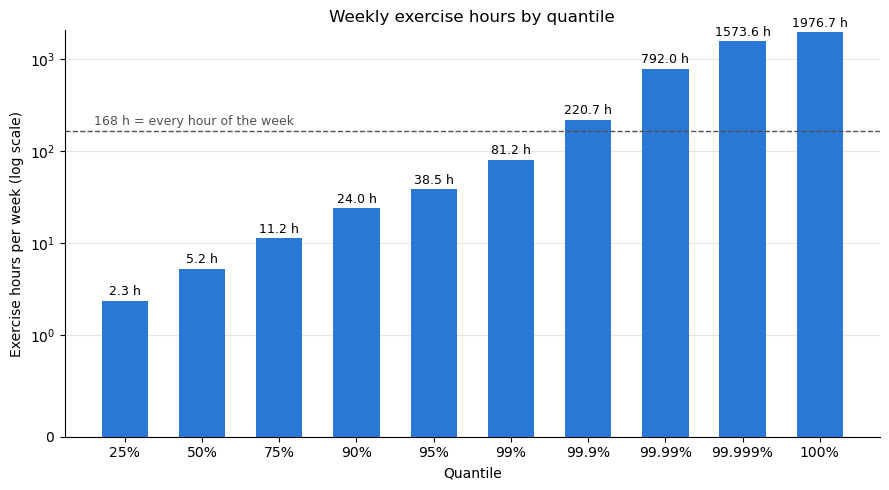

In [37]:
import matplotlib.pyplot as plt
hourly_df = pd.DataFrame(hourly_check_weekly)

fig, ax = plt.subplots(figsize=(9, 5))
labels = [f"{q:g}%" for q in hourly_df["quantile %"]]
bars = ax.bar(labels, hourly_df["hours"], color="#2a78d6", width=0.6)

# Value on top of each bar
for bar, h in zip(bars, hourly_df["hours"]):
    ax.annotate(f"{h:.1f} h", (bar.get_x() + bar.get_width() / 2, h),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)

# A week has 168 hours: anything above this line is impossible
ax.axhline(168, color="#52514e", linewidth=1, linestyle="--")
ax.text(-0.4, 168 * 1.15, "168 h = every hour of the week", color="#52514e", fontsize=9)

ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Quantile")
ax.set_ylabel("Exercise hours per week (log scale)")
ax.set_title("Weekly exercise hours by quantile")
ax.grid(axis="y", color="#e5e5e3", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


Considering that a week has 168h (24h per day), any practice value beyond 168h is mathematically impossible. At 99%, a consistent practice time of 81.2h per week (11h per day) seems also to be quite impossible even for profesionnal athletes. The most plausible value is found at 95% quantile (38.5h)

In [38]:
cap = clean_data["exercise_minutes_per_week"].quantile(0.95)
clean_data["exercise_minutes_per_week"] = clean_data["exercise_minutes_per_week"].clip(upper=cap)

Check for vigorous_exercise_minutes_per_week

In [39]:
check_activity_min = clean_data["vigorous_exercise_minutes_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])
hourly_check_weekly = {
    "quantile %": check_activity_min.index * 100,
    "minutes": check_activity_min,
    "hours":check_activity_min/60
    }
pd.DataFrame(hourly_check_weekly)

,quantile %,minutes,hours
0.25000,25.000,0.000,0.000000
0.50000,50.000,0.000,0.000000
0.75000,75.000,144.500,2.408333
0.90000,90.000,420.000,7.000000
0.95000,95.000,780.000,13.000000
0.99000,99.000,2100.000,35.000000
0.99900,99.900,4620.000,77.000000
0.99990,99.990,16051.320,267.522000
0.99999,99.999,43364.376,722.739600
1.00000,100.000,59301.000,988.350000


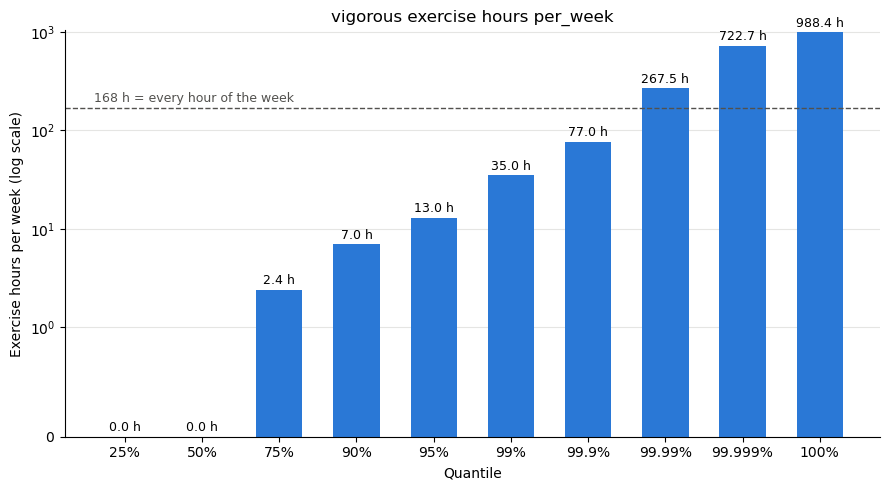

In [40]:
hourly_df = pd.DataFrame(hourly_check_weekly)

fig, ax = plt.subplots(figsize=(9, 5))
labels = [f"{q:g}%" for q in hourly_df["quantile %"]]
bars = ax.bar(labels, hourly_df["hours"], color="#2a78d6", width=0.6)

# Value on top of each bar
for bar, h in zip(bars, hourly_df["hours"]):
    ax.annotate(f"{h:.1f} h", (bar.get_x() + bar.get_width() / 2, h),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)

# A week has 168 hours: anything above this line is impossible
ax.axhline(168, color="#52514e", linewidth=1, linestyle="--")
ax.text(-0.4, 168 * 1.15, "168 h = every hour of the week", color="#52514e", fontsize=9)

ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Quantile")
ax.set_ylabel("Exercise hours per week (log scale)")
ax.set_title("vigorous exercise hours per_week")
ax.grid(axis="y", color="#e5e5e3", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


In [41]:
cap = clean_data["vigorous_exercise_minutes_per_week"].quantile(0.95)
clean_data["vigorous_exercise_minutes_per_week"] = clean_data["vigorous_exercise_minutes_per_week"].clip(upper=cap)

People who answered "no physical activity" (`physical_activity = 0`) were not asked how long they exercise, so BRFSS left their exercise minutes blank. Their real value is 0 minutes. The caps above were computed on active people only, before filling these zeros.

In [42]:
inactive = clean_data["physical_activity"] == 0
clean_data.loc[inactive, ["exercise_minutes_per_week", "vigorous_exercise_minutes_per_week"]] = 0

clean_data[["exercise_minutes_per_week", "vigorous_exercise_minutes_per_week"]].isna().mean() * 100

exercise_minutes_per_week             3.739889
vigorous_exercise_minutes_per_week    2.698346
dtype: float64

In [43]:
numeric_cols = ["bmi", "age", "height_inches", "weight_kg",
                "poor_physical_health_days", "poor_mental_health_days",
                "drinks_per_week", "drink_occasions_per_day",
                "exercise_minutes_per_week", "vigorous_exercise_minutes_per_week",
                "strength_training_per_week"]

clean_data[numeric_cols].describe()

,bmi,age,height_inches,weight_kg,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,strength_training_per_week
count,392119.000000,432339.000000,404602.000000,398482.000000,421667.000000,424355.000000,399739.000000,402612.000000,416170.000000,420673.000000,418108.000000
mean,28.477665,55.379346,67.066945,82.883083,4.478899,4.355040,2.738830,0.164305,401.479287,88.748978,1.863999
std,6.539546,17.909326,4.185244,21.331525,8.823183,8.316287,6.682283,0.271381,565.802171,190.844661,2.844207
min,12.020000,18.000000,36.000000,22.680000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.100000,41.000000,64.000000,68.040000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.400000,58.000000,67.000000,80.290000,0.000000,0.000000,0.230000,0.030000,182.000000,0.000000,0.467000
75%,31.620000,71.000000,70.000000,94.350000,4.000000,5.000000,2.330000,0.170000,495.000000,70.000000,3.000000
max,99.840000,80.000000,95.000000,284.000000,30.000000,30.000000,84.000000,1.000000,2310.000000,780.000000,97.000000


Similar with exercise per week, any value above the total number of hours per week (168h) is impossible and 11h constant exercise is not very plausible. We will also cap at 95% quantille.

At 99%, it is recorded at 4872 min, which is equivalent to 81.2h per week, 

In [44]:
X = clean_data[features]
Y = clean_data[TARGET]

Check for class Imbalance

In [45]:
classes = Y.value_counts()
target_class_imbalance = pd.DataFrame({
    "class": classes.index,
    "class_percentage %": (classes * 100 / len(Y)).round(2),
}).reset_index(drop=True)
target_class_imbalance

,class,class_percentage %
0,3.0,82.97
1,1.0,13.83
2,4.0,3.20


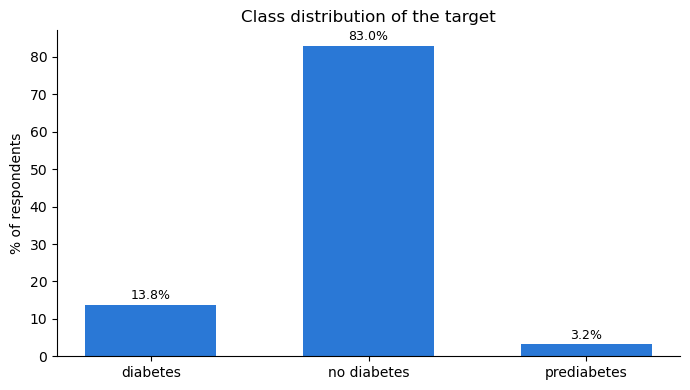

In [46]:
classes = Y.value_counts().sort_index()
target_class_imbalance = pd.DataFrame({
    "class": classes.index.astype(int).astype(str),
    "class_percentage": (classes / len(Y) * 100).round(2).values,
})

class_names = {"1": "diabetes", "2": "pregnancy only", "3": "no diabetes", "4": "prediabetes"}
labels = target_class_imbalance["class"].map(class_names)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, target_class_imbalance["class_percentage"], color="#2a78d6", width=0.6)
for bar, p in zip(bars, target_class_imbalance["class_percentage"]):
    ax.annotate(f"{p:.1f}%", (bar.get_x() + bar.get_width() / 2, p),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)
ax.set_ylabel("% of respondents")
ax.set_title("Class distribution of the target")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


In [47]:
import os
from datetime import datetime
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (roc_auc_score,
                             roc_curve,
                             accuracy_score,
                             balanced_accuracy_score,
                             precision_score,
                             recall_score,
                             precision_recall_curve,
                             average_precision_score,
                             f1_score,
                             fbeta_score,
                             make_scorer,
                             confusion_matrix,
                             classification_report)
from tensorboardX import SummaryWriter

RANDOM_STATE = 42
LOG_DIR = os.path.join(OUTPUT_DIR, "runs")   # view with: tensorboard --logdir runs
# 2 (diabetes only during pregnancy) was merged into 4 -> "at risk"
CLASS_NAMES = {1: "diabetes", 3: "no diabetes", 4: "at risk"}
CLASS_COLORS = {1: "#2a78d6", 3: "#1baf7a", 4: "#eda100"}   # one fixed color per class
FLAG_CLASSES = [1, 4]   # diabetes or at risk -> flagged for follow-up
results_log = []   # every experiment's summary lands here -> becomes your results table


# ---------- Screening = binary view: needs follow-up (diabetes or at risk) vs no diabetes ----------
def is_flagged(class_labels):
    return np.isin(np.asarray(class_labels), FLAG_CLASSES)

def screen_sensitivity(y_true, y_pred):
    return recall_score(is_flagged(y_true), is_flagged(y_pred), zero_division=0)

def screen_precision(y_true, y_pred):
    return precision_score(is_flagged(y_true), is_flagged(y_pred), zero_division=0)

def screen_specificity(y_true, y_pred):
    actually_flagged = is_flagged(y_true)
    predicted_flagged = is_flagged(y_pred)
    return (~predicted_flagged[~actually_flagged]).mean()

def screen_f1(y_true, y_pred):
    return f1_score(is_flagged(y_true), is_flagged(y_pred), zero_division=0)

def screen_f2(y_true, y_pred):
    return fbeta_score(is_flagged(y_true), is_flagged(y_pred), beta=2, zero_division=0)


def log_experiment(run_name, pipeline, config, X_train, y_train, X_val, y_val,
                   do_cv=True, use_tensorboard=True):
    '''
    Fits `pipeline`, evaluates it on the validation set, logs to TensorBoard,
    and records a row for the results table. Returns the fitted pipeline.

    run_name : short descriptive string, e.g. "logreg_balanced"
    config   : dict of whatever you want tracked, e.g. {"model": "LogisticRegression", "C": 1.0}
    '''
    pipeline.fit(X_train, y_train)
    classes = pipeline.classes_
    labels = [CLASS_NAMES.get(int(class_code), str(class_code)) for class_code in classes]

    val_probs = pipeline.predict_proba(X_val)
    val_preds = pipeline.predict(X_val)
    y_val_array = np.asarray(y_val)
    y_val_binarized = label_binarize(y_val_array, classes=classes)

    # ---------- 1. Main metrics: screening (diabetes or at risk = flagged) ----------
    flagged = is_flagged(val_preds)
    metrics = {
        "screen_sensitivity": screen_sensitivity(y_val_array, val_preds),
        "screen_precision": screen_precision(y_val_array, val_preds),
        "screen_f2": screen_f2(y_val_array, val_preds),
        "screen_f1": screen_f1(y_val_array, val_preds),
    }

    # ---------- 2. Per-group metrics ----------
    metrics["screen_specificity"] = screen_specificity(y_val_array, val_preds)
    metrics["pct_flagged"] = flagged.mean() * 100
    metrics["missed/diabetes"] = (val_preds[y_val_array == 1] == 3).mean()   # diabetes predicted as no diabetes
    for flag_class in FLAG_CLASSES:
        metrics[f"screen_sensitivity/{CLASS_NAMES[flag_class]}"] = flagged[y_val_array == flag_class].mean()

    per_class_precision = precision_score(y_val_array, val_preds, average=None, labels=classes, zero_division=0)
    per_class_recall = recall_score(y_val_array, val_preds, average=None, labels=classes, zero_division=0)
    per_class_f1 = f1_score(y_val_array, val_preds, average=None, labels=classes, zero_division=0)
    for class_index, class_name in enumerate(labels):
        class_is_true = y_val_binarized[:, class_index]
        class_probability = val_probs[:, class_index]
        metrics[f"val_precision/{class_name}"] = per_class_precision[class_index]
        metrics[f"val_recall/{class_name}"] = per_class_recall[class_index]   # = sensitivity for that class
        metrics[f"val_f1/{class_name}"] = per_class_f1[class_index]
        metrics[f"val_roc_auc/{class_name}"] = roc_auc_score(class_is_true, class_probability)
        metrics[f"val_pr_auc/{class_name}"] = average_precision_score(class_is_true, class_probability)

    # ---------- 3. Supporting metrics: overall model quality ----------
    metrics.update({
        "val_roc_auc_ovr": roc_auc_score(y_val_array, val_probs, multi_class="ovr", average="macro"),
        "val_f1_macro": f1_score(y_val_array, val_preds, average="macro", zero_division=0),
        "val_balanced_accuracy": balanced_accuracy_score(y_val_array, val_preds),
        "val_accuracy": accuracy_score(y_val_array, val_preds),
        "val_precision_macro": precision_score(y_val_array, val_preds, average="macro", zero_division=0),
        "val_recall_macro": recall_score(y_val_array, val_preds, average="macro", zero_division=0),
        "val_precision_weighted": precision_score(y_val_array, val_preds, average="weighted", zero_division=0),
        "val_recall_weighted": recall_score(y_val_array, val_preds, average="weighted", zero_division=0),
        "val_f1_weighted": f1_score(y_val_array, val_preds, average="weighted", zero_division=0),
    })

    # ---------- Cross-validation on the TRAINING data only ----------
    if do_cv:
        cv_scoring = {
            "screen_sensitivity": make_scorer(screen_sensitivity),
            "screen_precision": make_scorer(screen_precision),
            "screen_specificity": make_scorer(screen_specificity),
            "screen_f2": make_scorer(screen_f2),
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy",
            "precision_macro": "precision_macro",
            "recall_macro": "recall_macro",
            "f1_macro": "f1_macro",
            "roc_auc_ovr": "roc_auc_ovr",
        }
        cv_results = cross_validate(
            pipeline, X_train, y_train,
            cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE),
            scoring=cv_scoring,
            n_jobs=2,   # each parallel fold copies the data; more than 2 runs out of RAM locally
        )
        for score_name in cv_scoring:
            metrics[f"cv_{score_name}_mean"] = cv_results[f"test_{score_name}"].mean()
            metrics[f"cv_{score_name}_std"] = cv_results[f"test_{score_name}"].std()

    print(f"[{run_name}] SCREENING  sensitivity = {metrics['screen_sensitivity']:.3f} | "
          f"precision = {metrics['screen_precision']:.3f} | "
          f"F2 = {metrics['screen_f2']:.3f} | "
          f"F1 = {metrics['screen_f1']:.3f} | "
          f"specificity = {metrics['screen_specificity']:.3f} | "
          f"flagged = {metrics['pct_flagged']:.1f}%")
    print(f"    flagged: diabetes = {metrics['screen_sensitivity/diabetes']:.3f} | "
          f"at risk = {metrics['screen_sensitivity/at risk']:.3f} | "
          f"diabetics missed = {metrics['missed/diabetes']:.3f}")
    print(f"    OVERALL  ROC-AUC (OvR) = {metrics['val_roc_auc_ovr']:.4f} | "
          f"macro F1 = {metrics['val_f1_macro']:.4f} | "
          f"balanced acc = {metrics['val_balanced_accuracy']:.4f} | "
          f"accuracy = {metrics['val_accuracy']:.4f}")
    if do_cv:
        print(f"    CV  screening F2 = {metrics['cv_screen_f2_mean']:.4f} (+/- {metrics['cv_screen_f2_std']:.4f}) | "
              f"sensitivity = {metrics['cv_screen_sensitivity_mean']:.4f} (+/- {metrics['cv_screen_sensitivity_std']:.4f}) | "
              f"precision = {metrics['cv_screen_precision_mean']:.4f} (+/- {metrics['cv_screen_precision_std']:.4f}) | "
              f"macro F1 = {metrics['cv_f1_macro_mean']:.4f} (+/- {metrics['cv_f1_macro_std']:.4f})")
    print(classification_report(y_val_array, val_preds, labels=classes, target_names=labels,
                                digits=3, zero_division=0))

    # ---------- Confusion matrix: counts, colored by row % (= recall per class) ----------
    confusion_counts = confusion_matrix(y_val_array, val_preds, labels=classes)
    confusion_row_share = confusion_counts / confusion_counts.sum(axis=1, keepdims=True)
    fig_cm, cm_axis = plt.subplots(figsize=(6, 5))
    cm_axis.imshow(confusion_row_share, cmap="Blues", vmin=0, vmax=1)
    for row_index in range(len(classes)):
        for col_index in range(len(classes)):
            cell_share = confusion_row_share[row_index, col_index]
            cm_axis.text(col_index, row_index,
                         f"{confusion_counts[row_index, col_index]:,}\n({cell_share:.0%})",
                         ha="center", va="center", color="white" if cell_share > 0.5 else "black")
    cm_axis.set_xticks(range(len(classes)), labels, rotation=30, ha="right")
    cm_axis.set_yticks(range(len(classes)), labels)
    cm_axis.set_xlabel("Predicted"); cm_axis.set_ylabel("Actual"); cm_axis.set_title(run_name)
    fig_cm.tight_layout()

    # ---------- ROC and precision-recall curves (one-vs-rest, one curve per class) ----------
    fig_curves, (roc_axis, pr_axis) = plt.subplots(1, 2, figsize=(11, 4.5))
    for class_index, (class_code, class_name) in enumerate(zip(classes, labels)):
        color = CLASS_COLORS.get(int(class_code), "#52514e")
        class_is_true = y_val_binarized[:, class_index]
        class_probability = val_probs[:, class_index]

        false_positive_rate, true_positive_rate, _ = roc_curve(class_is_true, class_probability)
        roc_axis.plot(false_positive_rate, true_positive_rate, color=color, linewidth=2,
                      label=f"{class_name} (AUC={metrics[f'val_roc_auc/{class_name}']:.2f})")

        precision_values, recall_values, _ = precision_recall_curve(class_is_true, class_probability)
        pr_axis.plot(recall_values, precision_values, color=color, linewidth=2,
                     label=f"{class_name} (AP={metrics[f'val_pr_auc/{class_name}']:.2f})")
        pr_axis.axhline(class_is_true.mean(), color=color, linewidth=1, linestyle=":")  # random-guess level

    roc_axis.plot([0, 1], [0, 1], color="#52514e", linewidth=1, linestyle="--")
    roc_axis.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (one-vs-rest)")
    pr_axis.set(xlabel="Recall", ylabel="Precision", title="Precision-recall (one-vs-rest)")
    for curve_axis in (roc_axis, pr_axis):
        curve_axis.legend(fontsize=8)
        for side in ["top", "right"]:
            curve_axis.spines[side].set_visible(False)
    fig_curves.suptitle(run_name)
    fig_curves.tight_layout()

    # ---------- TensorBoard ----------
    if use_tensorboard:
        try:
            timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
            writer = SummaryWriter(os.path.join(LOG_DIR, f"{run_name}_{timestamp}"))
            for metric_name, metric_value in metrics.items():
                writer.add_scalar(metric_name, metric_value, 0)
            writer.add_figure("confusion_matrix", fig_cm, 0, close=False)
            writer.add_figure("roc_pr_curves", fig_curves, 0, close=False)
            writer.add_text("config", str(config), 0)
            # hparams tab: compare runs side by side
            hparams = {param_name: (param_value if isinstance(param_value, (int, float, str, bool))
                                    else str(param_value))
                       for param_name, param_value in config.items()}
            writer.add_hparams(hparams, {f"hparam/{metric_name}": metric_value
                                         for metric_name, metric_value in metrics.items()
                                         if "/" not in metric_name})
            writer.close()
        except Exception as error:
            print(f"  (TensorBoard logging failed for this run: {error} — local results still recorded below)")

    plt.show()

    results_log.append({
        "run_name": run_name,
        **config,
        **{metric_name: round(float(metric_value), 4) for metric_name, metric_value in metrics.items()},
    })
    return pipeline


In [48]:
X_temp, X_test, Y_temp, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=RANDOM_STATE, stratify=Y
)

X_train, X_val, Y_train, Y_val = train_test_split(
    X_temp, Y_temp, test_size=0.25, random_state=RANDOM_STATE, stratify=Y_temp
)

print(len(X_train), len(X_val), len(X_test))   # ≈ 259k / 86k / 86k


259403 86468 86468


In [49]:
# Save train, validation and test sets (features + target in one file each)
train_df = X_train.assign(diabetes=Y_train)
val_df   = X_val.assign(diabetes=Y_val)
test_df  = X_test.assign(diabetes=Y_test)

train_df.to_csv(os.path.join(DATA_DIR, "diabete_study_train.csv"), index=False)
val_df.to_csv(os.path.join(DATA_DIR, "diabete_study_val.csv"), index=False)
test_df.to_csv(os.path.join(DATA_DIR, "diabete_study_test.csv"), index=False)


In [50]:
numeric_cols = ["bmi", "age", "height_inches", "weight_kg",
                "poor_physical_health_days", "poor_mental_health_days",
                "drinks_per_week", "drink_occasions_per_day",
                "exercise_minutes_per_week", "vigorous_exercise_minutes_per_week",
                "strength_training_per_week"]
cat_cols = ["general_health", "age_group", "education", "income",
            "smoking_status", "cholesterol_check",
            "high_cholesterol"]   # 0 = no, 1 = yes, -1 = unknown -> one-hot
binary_cols = ["high_blood_pressure", "stroke", "heart_disease",
               "kidney_disease", "physical_activity", "heavy_drinker",
               "health_insurance", "cant_afford_doctor", "difficulty_walking", "sex"]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), binary_cols),
])
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

[logreg_baseline] SCREENING  sensitivity = 0.824 | precision = 0.297 | F2 = 0.609 | F1 = 0.437 | specificity = 0.600 | flagged = 47.2%
    flagged: diabetes = 0.855 | at risk = 0.692 | diabetics missed = 0.145
    OVERALL  ROC-AUC (OvR) = 0.7447 | macro F1 = 0.4235 | balanced acc = 0.5294 | accuracy = 0.5989
              precision    recall  f1-score   support

    diabetes      0.340     0.651     0.447     11957
 no diabetes      0.943     0.600     0.734     71742
     at risk      0.052     0.337     0.090      2769

    accuracy                          0.599     86468
   macro avg      0.445     0.529     0.424     86468
weighted avg      0.831     0.599     0.673     86468



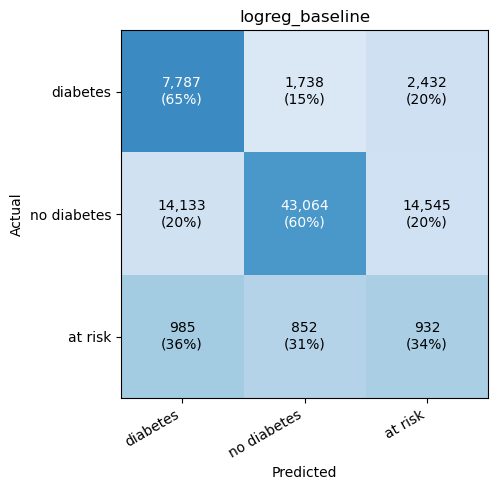

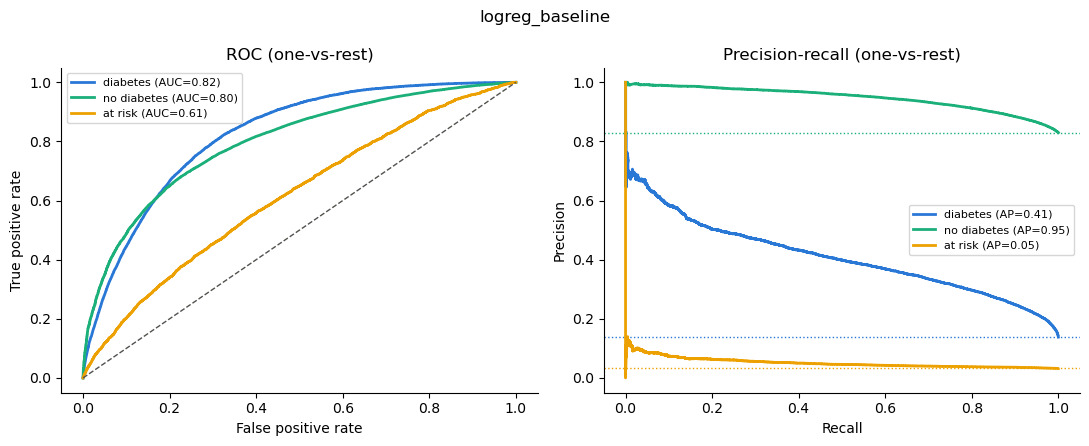

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](3,)","[1.,3.,4.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](28,)","['bmi','poor_physical_health_days','poor_mental_health_days',..., 'cant_afford_doctor','difficulty_walking','sex']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By

In [49]:
baseline_pipeline = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        C=1.0,
        solver="lbfgs",
        random_state=RANDOM_STATE)),
])

config = {"model": "LogisticRegression", "class_weight": "balanced", "C": 1.0,
          "solver": "lbfgs", "max_iter": 1000, "ordinal_encoding": "onehot"}

log_experiment("logreg_baseline", baseline_pipeline, config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


In [50]:
baseline_results = results_log[-1]   # most recent run

screening_summary = pd.DataFrame({
    "metric": [
        "Diabetes: predicted exactly as diabetes (recall)",
        "Diabetes: flagged as diabetes or at risk",
        "Diabetes: missed (predicted no diabetes)",
        "At risk: predicted exactly as at risk (recall)",
        "At risk: flagged as diabetes or at risk",
        "Screening sensitivity (diabetes + at risk combined)",
        "Screening precision (flagged people who truly need follow-up)",
        "Screening specificity (healthy people not flagged)",
        "Screening F2",
        "Screening F1",
        "People flagged (%)",
    ],
    "value": [
        baseline_results["val_recall/diabetes"],
        baseline_results["screen_sensitivity/diabetes"],
        baseline_results["missed/diabetes"],
        baseline_results["val_recall/at risk"],
        baseline_results["screen_sensitivity/at risk"],
        baseline_results["screen_sensitivity"],
        baseline_results["screen_precision"],
        baseline_results["screen_specificity"],
        baseline_results["screen_f2"],
        baseline_results["screen_f1"],
        baseline_results["pct_flagged"],
    ],
})
screening_summary


,metric,value
0,Diabetes: predicted exactly as diabetes (recall),0.6513
1,Diabetes: flagged as diabetes or at risk,0.8546
2,Diabetes: missed (predicted no diabetes),0.1454
3,At risk: predicted exactly as at risk (recall),0.3366
4,At risk: flagged as diabetes or at risk,0.6923
5,Screening sensitivity (diabetes + at risk comb...,0.8241
6,Screening precision (flagged people who truly ...,0.2973
7,Screening specificity (healthy people not flag...,0.6003
8,Screening F2,0.6085
9,Screening F1,0.4370


## Experiment 2: Apply downsampling the majority class, then upsampling the minority class, then reuse the same baseline logistic regression without class weight

[logreg_under_smotenc] SCREENING  sensitivity = 0.597 | precision = 0.361 | F2 = 0.528 | F1 = 0.450 | specificity = 0.783 | flagged = 28.2%
    flagged: diabetes = 0.638 | at risk = 0.420 | diabetics missed = 0.362
    OVERALL  ROC-AUC (OvR) = 0.7248 | macro F1 = 0.4524 | balanced acc = 0.4834 | accuracy = 0.7226
              precision    recall  f1-score   support

    diabetes      0.399     0.487     0.438     11957
 no diabetes      0.904     0.783     0.839     71742
     at risk      0.051     0.181     0.080      2769

    accuracy                          0.723     86468
   macro avg      0.451     0.483     0.452     86468
weighted avg      0.807     0.723     0.759     86468



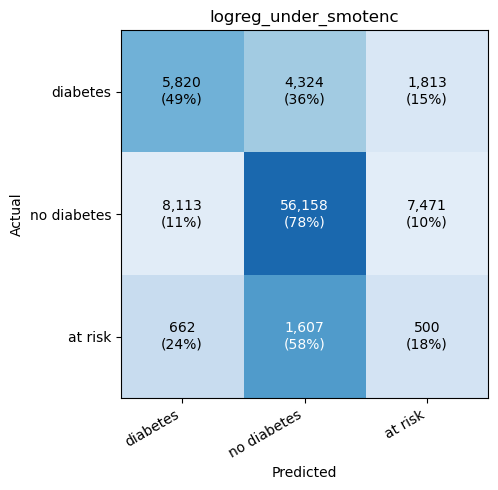

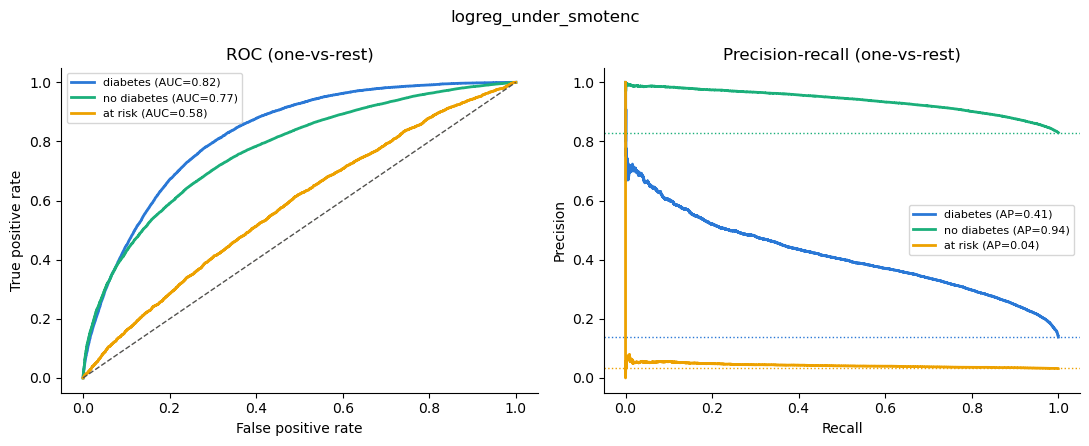

,steps,"[('impute', ...), ('undersample', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[float64](3,)","[1.,3.,4.]"
feature_names_in_,"ndarray[object](28,)","['bmi','poor_physical_health_days','poor_mental_health_days',..., 'cant_afford_doctor','difficulty_walking','sex']"
n_features_in_,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'


In [51]:
from collections import Counter
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTENC


def undersample_no_diabetes(class_labels):
    """Keep 'no diabetes' (3) at 3x the number of diabetes cases."""
    class_counts = Counter(class_labels)
    return {3: min(class_counts[3], 3 * class_counts[1])}


def oversample_minorities(class_labels):
    """Grow diabetes (1) and at risk (4) to half the size of the (undersampled) majority."""
    class_counts = Counter(class_labels)
    target_count = class_counts[3] // 2
    return {1: max(class_counts[1], target_count), 4: max(class_counts[4], target_count)}


# Step 1: impute only (SMOTENC needs the original categories, before one-hot encoding)
impute_step = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", SimpleImputer(strategy="most_frequent"), cat_cols + binary_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

# Step 2: scale and one-hot encode, after resampling
encode_step = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", binary_cols),
])

resampled_pipeline = ImbPipeline([
    ("impute", impute_step),
    ("undersample", RandomUnderSampler(sampling_strategy=undersample_no_diabetes,
                                       random_state=RANDOM_STATE)),
    ("oversample", SMOTENC(categorical_features=cat_cols + binary_cols,
                           sampling_strategy=oversample_minorities,
                           random_state=RANDOM_STATE)),
    ("encode", encode_step),
    ("clf", LogisticRegression(max_iter=1000, C=1.0, solver="lbfgs",
                               random_state=RANDOM_STATE)),   # no class_weight: resampling handles the imbalance
])

resampled_config = {"model": "LogisticRegression", "C": 1.0, "class_weight": "none",
                    "resampling": "undersample 3x + SMOTENC to 1/2"}

log_experiment("logreg_under_smotenc", resampled_pipeline, resampled_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


## Experiment 3: Oversampling to the majority class only

[logreg_smotenc_1to1] SCREENING  sensitivity = 0.720 | precision = 0.279 | F2 = 0.547 | F1 = 0.402 | specificity = 0.618 | flagged = 43.9%
    flagged: diabetes = 0.751 | at risk = 0.584 | diabetics missed = 0.249
    OVERALL  ROC-AUC (OvR) = 0.7011 | macro F1 = 0.4158 | balanced acc = 0.4898 | accuracy = 0.6012
              precision    recall  f1-score   support

    diabetes      0.353     0.574     0.437     11957
 no diabetes      0.915     0.618     0.738     71742
     at risk      0.041     0.277     0.072      2769

    accuracy                          0.601     86468
   macro avg      0.437     0.490     0.416     86468
weighted avg      0.809     0.601     0.675     86468



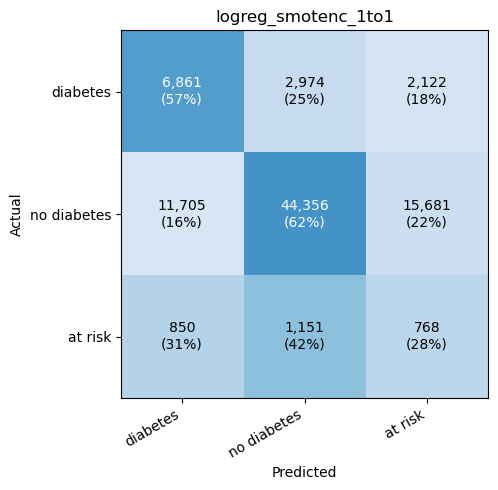

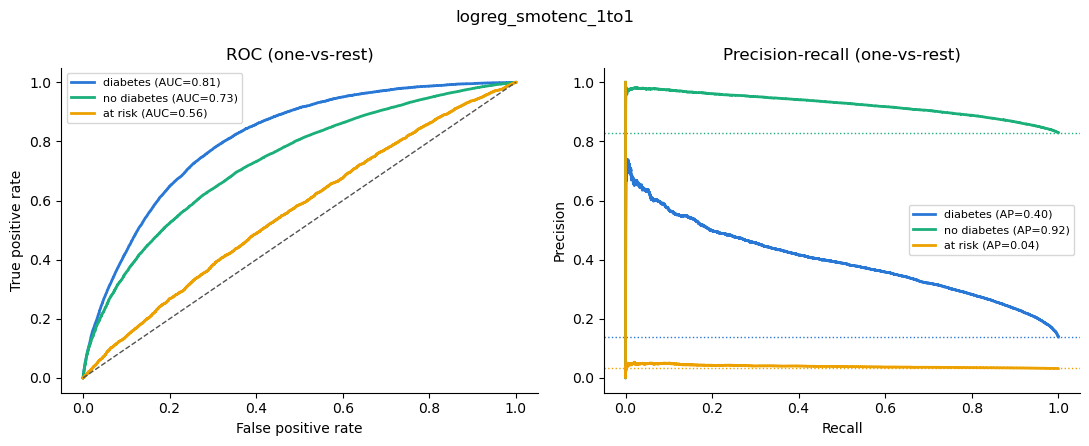

,steps,"[('impute', ...), ('oversample', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[float64](3,)","[1.,3.,4.]"
feature_names_in_,"ndarray[object](28,)","['bmi','poor_physical_health_days','poor_mental_health_days',..., 'cant_afford_doctor','difficulty_walking','sex']"
n_features_in_,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'


In [52]:
from collections import Counter
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC


def oversample_to_majority(class_labels, share_of_majority=1.0):
    """Grow diabetes (1) and at risk (4) to a share of the 'no diabetes' (3) count."""
    class_counts = Counter(class_labels)
    target_count = int(class_counts[3] * share_of_majority)
    return {1: max(class_counts[1], target_count), 4: max(class_counts[4], target_count)}


# Step 1: impute only (SMOTENC needs the original categories, before one-hot encoding)
impute_step = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", SimpleImputer(strategy="most_frequent"), cat_cols + binary_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

# Step 2: scale and one-hot encode, after resampling
encode_step = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", binary_cols),
])

oversample_pipeline = ImbPipeline([
    ("impute", impute_step),
    ("oversample", SMOTENC(categorical_features=cat_cols + binary_cols,
                           sampling_strategy=oversample_to_majority,
                           random_state=RANDOM_STATE)),
    ("encode", encode_step),
    ("clf", LogisticRegression(max_iter=1000, C=1.0, solver="lbfgs",
                               random_state=RANDOM_STATE)),   # no class_weight: resampling handles it
])

oversample_config = {"model": "LogisticRegression", "C": 1.0, "class_weight": "none",
                     "resampling": "SMOTENC to 1:1:1, no undersampling"}

log_experiment("logreg_smotenc_1to1", oversample_pipeline, oversample_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


## Training with Ensemble Model: Random Forest

[rf_depth6_leaf50_estimators_500] SCREENING  sensitivity = 0.819 | precision = 0.301 | F2 = 0.609 | F1 = 0.440 | specificity = 0.609 | flagged = 46.4%
    flagged: diabetes = 0.852 | at risk = 0.679 | diabetics missed = 0.148
    OVERALL  ROC-AUC (OvR) = 0.7459 | macro F1 = 0.4219 | balanced acc = 0.5279 | accuracy = 0.6156
              precision    recall  f1-score   support

    diabetes      0.306     0.746     0.434     11957
 no diabetes      0.943     0.609     0.740     71742
     at risk      0.058     0.229     0.092      2769

    accuracy                          0.616     86468
   macro avg      0.435     0.528     0.422     86468
weighted avg      0.826     0.616     0.677     86468



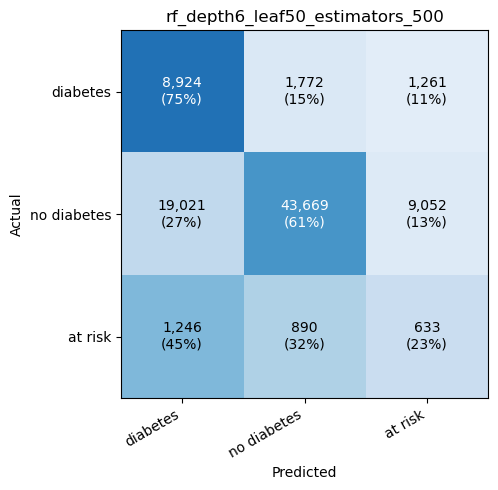

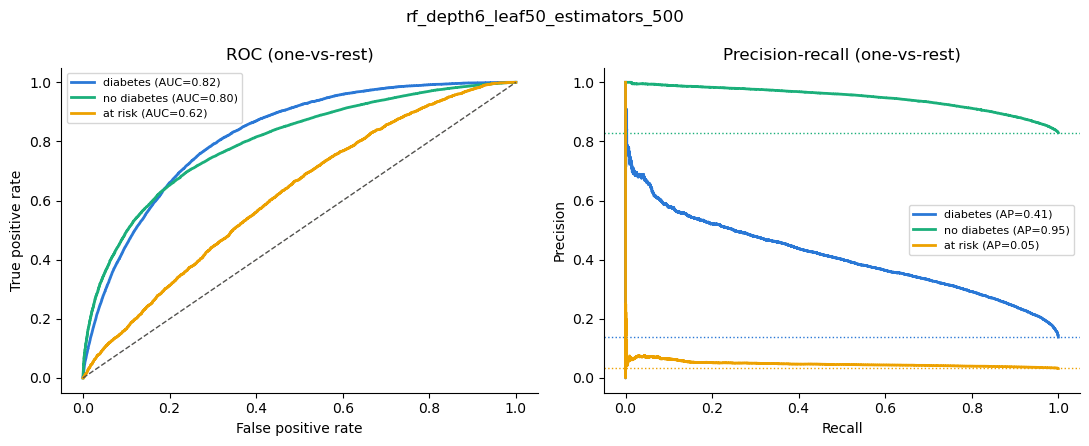

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider

In [53]:
forest_model = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced_subsample",
    max_depth=6,
    min_samples_leaf=50,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 500,
                 "class_weight": "balanced_subsample", "max_depth": 6,
                 "min_samples_leaf": 50, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth6_leaf50_estimators_500", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


[rf_depth12_leaf100_estimators_1000] SCREENING  sensitivity = 0.809 | precision = 0.310 | F2 = 0.612 | F1 = 0.449 | specificity = 0.631 | flagged = 44.4%
    flagged: diabetes = 0.844 | at risk = 0.659 | diabetics missed = 0.156
    OVERALL  ROC-AUC (OvR) = 0.7533 | macro F1 = 0.4300 | balanced acc = 0.5304 | accuracy = 0.6339
              precision    recall  f1-score   support

    diabetes      0.312     0.748     0.440     11957
 no diabetes      0.942     0.631     0.756     71742
     at risk      0.061     0.212     0.094      2769

    accuracy                          0.634     86468
   macro avg      0.438     0.530     0.430     86468
weighted avg      0.826     0.634     0.691     86468



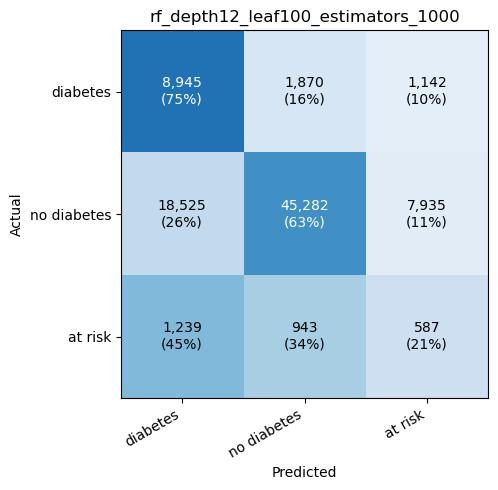

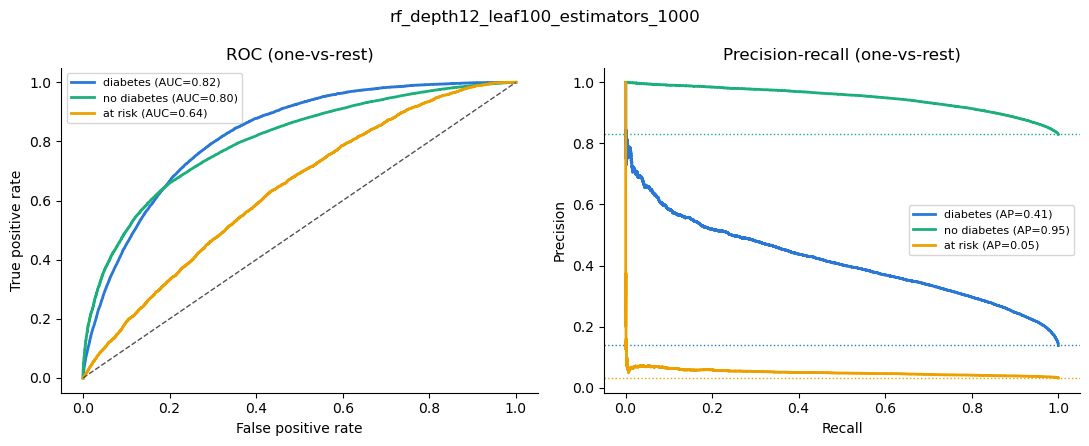

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",100
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consi

In [54]:
forest_model = RandomForestClassifier(
    n_estimators=1000,
    class_weight="balanced_subsample",
    max_depth=12,
    min_samples_leaf=100,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 1000,
                 "class_weight": "balanced_subsample", "max_depth": 12,
                 "min_samples_leaf": 100, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth12_leaf100_estimators_1000", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


[rf_depth12_leaf100_estimators_2000] SCREENING  sensitivity = 0.809 | precision = 0.310 | F2 = 0.612 | F1 = 0.449 | specificity = 0.631 | flagged = 44.4%
    flagged: diabetes = 0.844 | at risk = 0.660 | diabetics missed = 0.156
    OVERALL  ROC-AUC (OvR) = 0.7533 | macro F1 = 0.4302 | balanced acc = 0.5309 | accuracy = 0.6339
              precision    recall  f1-score   support

    diabetes      0.312     0.748     0.440     11957
 no diabetes      0.942     0.631     0.756     71742
     at risk      0.061     0.214     0.095      2769

    accuracy                          0.634     86468
   macro avg      0.438     0.531     0.430     86468
weighted avg      0.826     0.634     0.691     86468



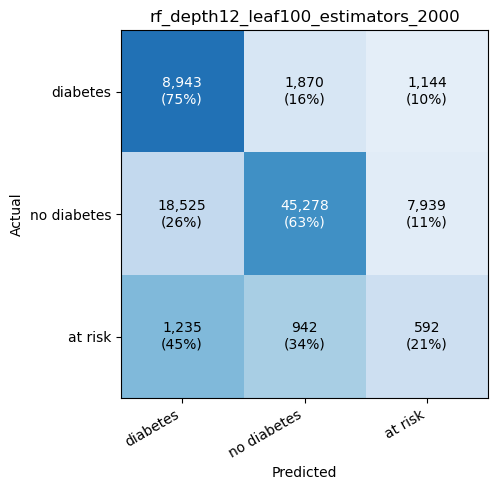

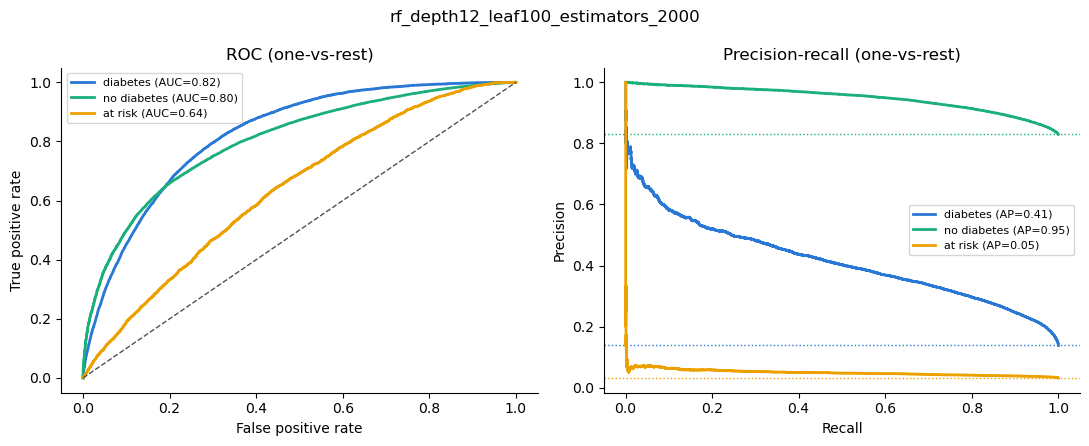

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",2000
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",100
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consi

In [55]:
forest_model = RandomForestClassifier(
    n_estimators=2000,
    class_weight="balanced_subsample",
    max_depth=12,
    min_samples_leaf=100,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 2000,
                 "class_weight": "balanced_subsample", "max_depth": 12,
                 "min_samples_leaf": 100, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth12_leaf100_estimators_2000", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


[rf_depth18_leaf200_estimators_2000] SCREENING  sensitivity = 0.817 | precision = 0.306 | F2 = 0.612 | F1 = 0.445 | specificity = 0.619 | flagged = 45.5%
    flagged: diabetes = 0.850 | at risk = 0.675 | diabetics missed = 0.150
    OVERALL  ROC-AUC (OvR) = 0.7519 | macro F1 = 0.4271 | balanced acc = 0.5314 | accuracy = 0.6236
              precision    recall  f1-score   support

    diabetes      0.312     0.740     0.439     11957
 no diabetes      0.943     0.619     0.747     71742
     at risk      0.059     0.235     0.094      2769

    accuracy                          0.624     86468
   macro avg      0.438     0.531     0.427     86468
weighted avg      0.827     0.624     0.684     86468



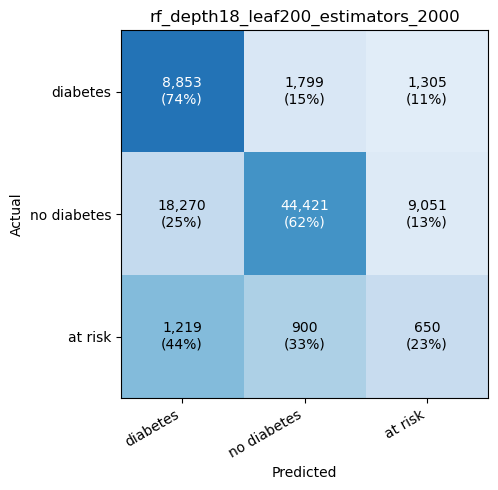

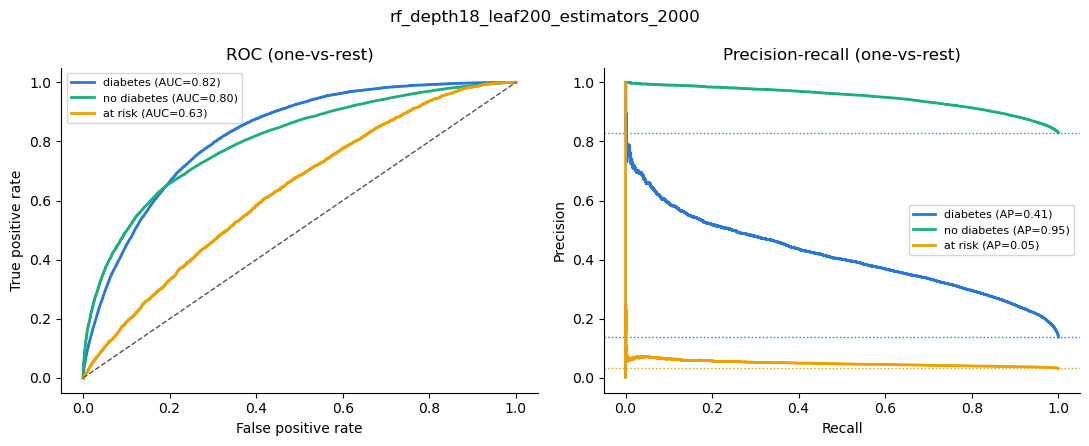

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",2000
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",18
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consi

In [56]:
forest_model = RandomForestClassifier(
    n_estimators=2000,
    class_weight="balanced_subsample",
    max_depth=18,
    min_samples_leaf=200,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 2000,
                 "class_weight": "balanced_subsample", "max_depth": 18,
                 "min_samples_leaf": 200, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth18_leaf200_estimators_2000", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


## Notice
Across the random forest variants tested so far, none outperformed the logistic regression baseline on screening F2 (best = 0.61 for both). Since random forests can capture non-linear effects and interactions between features, this suggests that the relationship between the survey answers and diabetes status is largely additive, a pattern a linear model already captures well. It also suggests that several features add little information beyond others (for example, age_group repeats age, and bmi combines height_inches and weight_kg).

To quantify each feature's contribution, we run permutation importance on the baseline logistic regression model: each feature is shuffled in turn, and the resulting drop in screening F2 on the validation set measures how much the model relies on it.


In [57]:
fitted_baseline = baseline_pipeline   # already fitted by log_experiment

importance_result = permutation_importance(
    fitted_baseline, X_val, Y_val,
    scoring=make_scorer(screen_f2),
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=2,
)

feature_importance = pd.DataFrame({
    "feature": X_val.columns,
    "f2_drop_mean": importance_result.importances_mean,
    "f2_drop_std": importance_result.importances_std,
}).sort_values("f2_drop_mean", ascending=False)

feature_importance


,feature,f2_drop_mean,f2_drop_std
5,age,0.039468,0.001080
11,general_health,0.032031,0.002012
17,high_blood_pressure,0.021212,0.001305
18,high_cholesterol,0.017498,0.001155
0,bmi,0.008862,0.000549
4,drink_occasions_per_day,0.008171,0.000631
16,cholesterol_check,0.007771,0.000715
7,weight_kg,0.005989,0.000605
12,age_group,0.005428,0.001138
20,heart_disease,0.002318,0.000334


Attempt training baseline with 13 features

[logreg_13_features] SCREENING  sensitivity = 0.810 | precision = 0.305 | F2 = 0.609 | F1 = 0.443 | specificity = 0.621 | flagged = 45.3%
    flagged: diabetes = 0.846 | at risk = 0.658 | diabetics missed = 0.154
    OVERALL  ROC-AUC (OvR) = 0.7396 | macro F1 = 0.4252 | balanced acc = 0.5224 | accuracy = 0.6147
              precision    recall  f1-score   support

    diabetes      0.330     0.651     0.438     11957
 no diabetes      0.941     0.621     0.748     71742
     at risk      0.053     0.295     0.089      2769

    accuracy                          0.615     86468
   macro avg      0.441     0.522     0.425     86468
weighted avg      0.828     0.615     0.684     86468



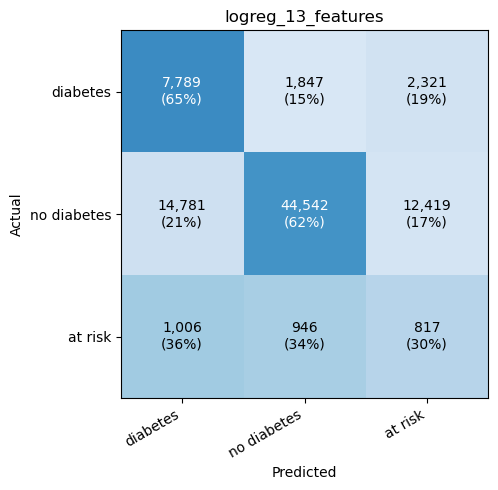

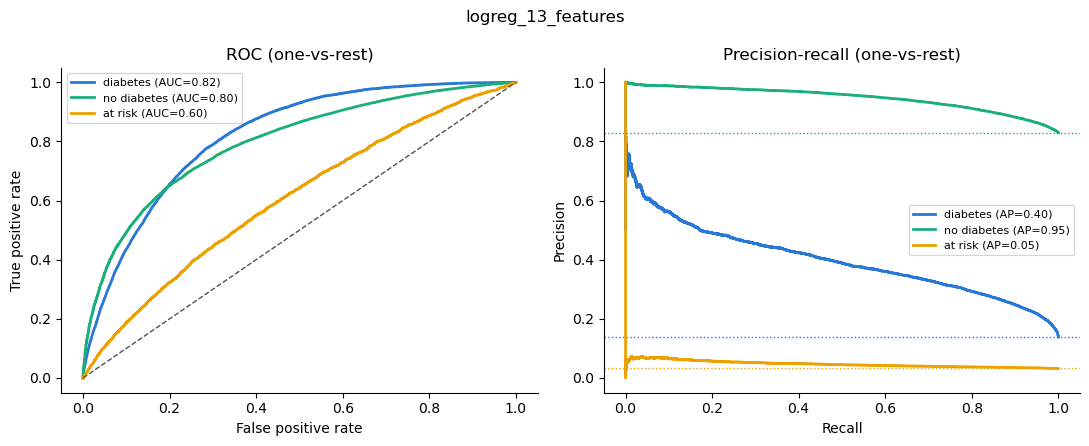

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](3,)","[1.,3.,4.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','bmi','weight_kg',...,'heart_disease','kidney_disease', 'difficulty_walking']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passt

In [58]:
selected_features = [
    # numeric
    "age", "bmi", "weight_kg", "drink_occasions_per_day",
    # ordinal / categorical
    "general_health", "cholesterol_check", "high_cholesterol", "education", "income",
    # binary
    "high_blood_pressure", "heart_disease", "kidney_disease", "difficulty_walking",
]

selected_numeric_cols = [column for column in numeric_cols if column in selected_features]
selected_cat_cols = [column for column in cat_cols if column in selected_features]
selected_binary_cols = [column for column in binary_cols if column in selected_features]

selected_preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), selected_numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), selected_cat_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), selected_binary_cols),
])

selected_pipeline = Pipeline([
    ("prep", selected_preprocess),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", C=1.0,
                               solver="lbfgs", random_state=RANDOM_STATE)),
])

selected_config = {"model": "LogisticRegression", "class_weight": "balanced", "C": 1.0,
                   "n_features": len(selected_features), "features": "top-13 by permutation F2"}

log_experiment("logreg_13_features", selected_pipeline, selected_config,
               X_train[selected_features], Y_train, X_val[selected_features], Y_val, do_cv=False)


[lgbm_baseline] SCREENING  sensitivity = 0.796 | precision = 0.319 | F2 = 0.612 | F1 = 0.455 | specificity = 0.651 | flagged = 42.5%
    flagged: diabetes = 0.831 | at risk = 0.645 | diabetics missed = 0.169
    OVERALL  ROC-AUC (OvR) = 0.7516 | macro F1 = 0.4354 | balanced acc = 0.5274 | accuracy = 0.6460
              precision    recall  f1-score   support

    diabetes      0.325     0.718     0.447     11957
 no diabetes      0.940     0.651     0.769     71742
     at risk      0.057     0.213     0.090      2769

    accuracy                          0.646     86468
   macro avg      0.440     0.527     0.435     86468
weighted avg      0.826     0.646     0.703     86468



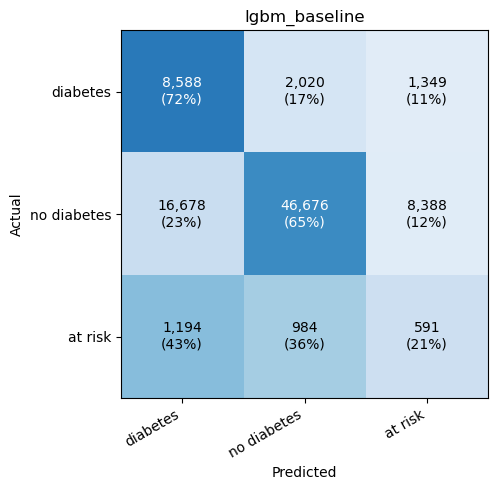

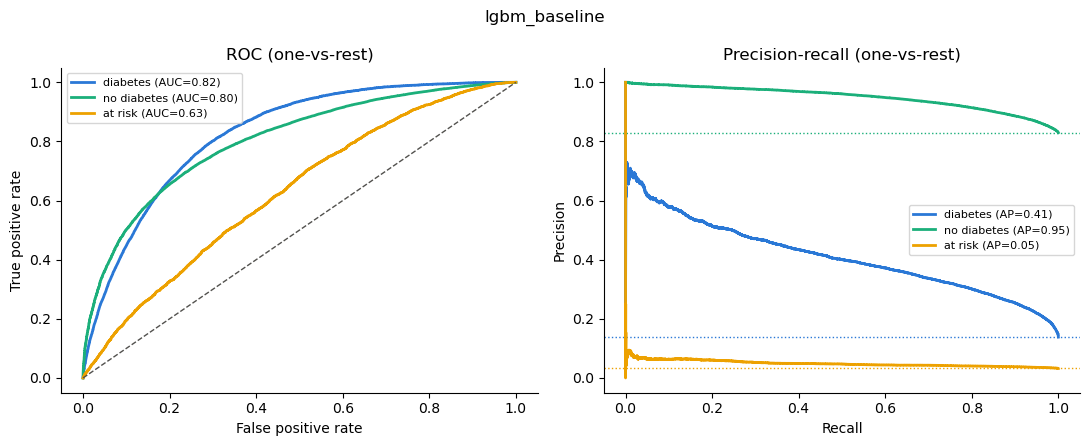

,learning_rate,0.05
,n_estimators,1000
,class_weight,'balanced'
,min_child_samples,50
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,42
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'


In [59]:
from lightgbm import LGBMClassifier

lightgbm_model = LGBMClassifier(
    class_weight="balanced",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=50,      # like min_samples_leaf in the forest: lets the class weights work
    subsample=0.8,             # each tree sees 80% of the rows...
    subsample_freq=1,          # ...re-drawn for every tree
    colsample_bytree=0.8,      # each tree sees 80% of the features
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,                # hide LightGBM's training messages
)

lightgbm_config = {"model": "LightGBM", "class_weight": "balanced", "n_estimators": 1000,
                   "learning_rate": 0.05, "num_leaves": 31, "min_child_samples": 50,
                   "subsample": 0.8, "colsample_bytree": 0.8, "categorical": "ordinal as numbers"}

log_experiment("lgbm_baseline", lightgbm_model, lightgbm_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


In [60]:
fitted_lightgbm = lightgbm_model   # already fitted by log_experiment

lightgbm_importance_result = permutation_importance(
    fitted_lightgbm, X_val, Y_val,
    scoring=make_scorer(screen_f2),
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=2,
)

lightgbm_feature_importance = pd.DataFrame({
    "feature": X_val.columns,
    "f2_drop_mean": lightgbm_importance_result.importances_mean,
    "f2_drop_std": lightgbm_importance_result.importances_std,
}).sort_values("f2_drop_mean", ascending=False)

lightgbm_feature_importance


,feature,f2_drop_mean,f2_drop_std
11,general_health,0.028813,0.001630
5,age,0.023822,0.000902
17,high_blood_pressure,0.019881,0.001799
18,high_cholesterol,0.015342,0.000472
0,bmi,0.013252,0.001724
12,age_group,0.012666,0.000763
16,cholesterol_check,0.010522,0.000910
4,drink_occasions_per_day,0.007742,0.001285
3,drinks_per_week,0.005621,0.001053
7,weight_kg,0.003276,0.001441


[lgbm_18_clinical_original] SCREENING  sensitivity = 0.804 | precision = 0.310 | F2 = 0.609 | F1 = 0.447 | specificity = 0.632 | flagged = 44.2%
    flagged: diabetes = 0.839 | at risk = 0.650 | diabetics missed = 0.161
    OVERALL  ROC-AUC (OvR) = 0.7495 | macro F1 = 0.4302 | balanced acc = 0.5278 | accuracy = 0.6307
              precision    recall  f1-score   support

    diabetes      0.323     0.714     0.444     11957
 no diabetes      0.940     0.632     0.756     71742
     at risk      0.056     0.237     0.090      2769

    accuracy                          0.631     86468
   macro avg      0.439     0.528     0.430     86468
weighted avg      0.826     0.631     0.691     86468



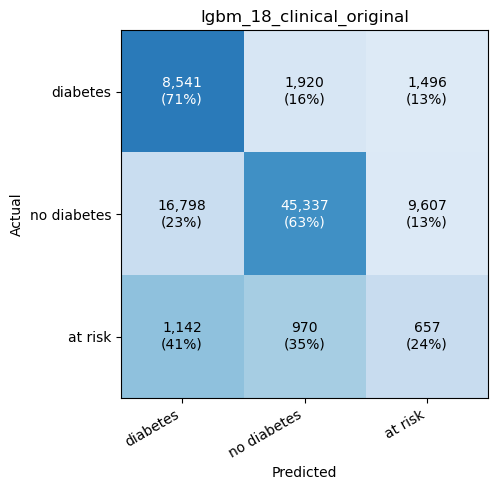

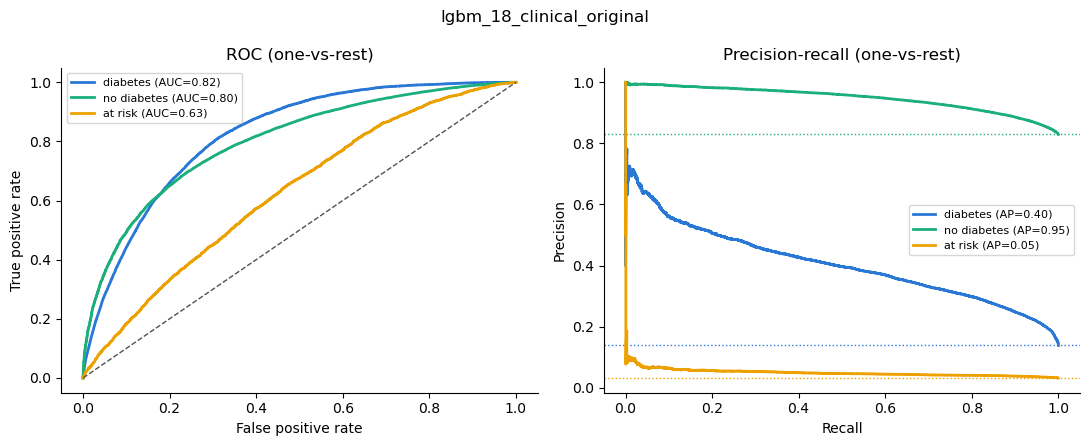

,learning_rate,0.05
,n_estimators,1000
,class_weight,'balanced'
,min_child_samples,50
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,42
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'


In [61]:
# train with selected value
selected_features = [
    # numeric
    "age", "bmi", "weight_kg", "drink_occasions_per_day", "drinks_per_week",
    "exercise_minutes_per_week",
    # ordinal / categorical
    "general_health", "high_cholesterol", "cholesterol_check", "smoking_status",
    # binary
    "high_blood_pressure", "sex", "kidney_disease", "heart_disease",
    "difficulty_walking", "physical_activity", "stroke", "heavy_drinker", 
]

lightgbm_model = LGBMClassifier(
    class_weight="balanced",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=50,      # like min_samples_leaf in the forest: lets the class weights work
    subsample=0.8,             # each tree sees 80% of the rows...
    subsample_freq=1,          # ...re-drawn for every tree
    colsample_bytree=0.8,      # each tree sees 80% of the features
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,                # hide LightGBM's training messages
)

lightgbm_config = {"model": "LightGBM", "class_weight": "balanced", "n_estimators": 1000,
                   "learning_rate": 0.05, "num_leaves": 31, "min_child_samples": 50,
                   "subsample": 0.8, "colsample_bytree": 0.8, "categorical": "ordinal as numbers"}

lightgbm_reduced_config = {**lightgbm_config, "n_features": len(selected_features),
                           "features": "18: permutation F2 + clinical risk factors"}

log_experiment("lgbm_18_clinical_original", lightgbm_model, lightgbm_reduced_config,
               X_train[selected_features], Y_train, X_val[selected_features], Y_val, do_cv=False)


[logreg_splines_age_bmi] SCREENING  sensitivity = 0.826 | precision = 0.297 | F2 = 0.609 | F1 = 0.437 | specificity = 0.599 | flagged = 47.3%
    flagged: diabetes = 0.856 | at risk = 0.694 | diabetics missed = 0.144
    OVERALL  ROC-AUC (OvR) = 0.7454 | macro F1 = 0.4234 | balanced acc = 0.5295 | accuracy = 0.5981
              precision    recall  f1-score   support

    diabetes      0.341     0.652     0.448     11957
 no diabetes      0.944     0.599     0.733     71742
     at risk      0.052     0.337     0.090      2769

    accuracy                          0.598     86468
   macro avg      0.445     0.529     0.423     86468
weighted avg      0.832     0.598     0.673     86468



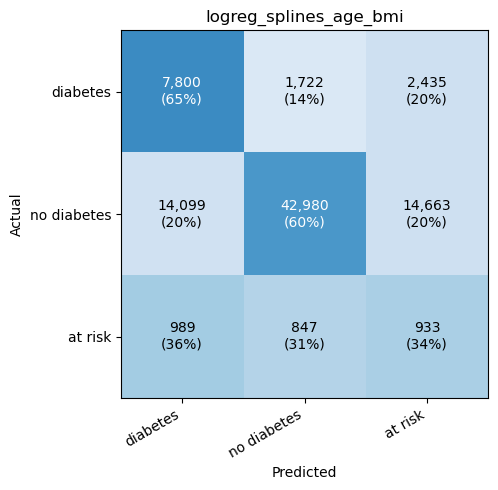

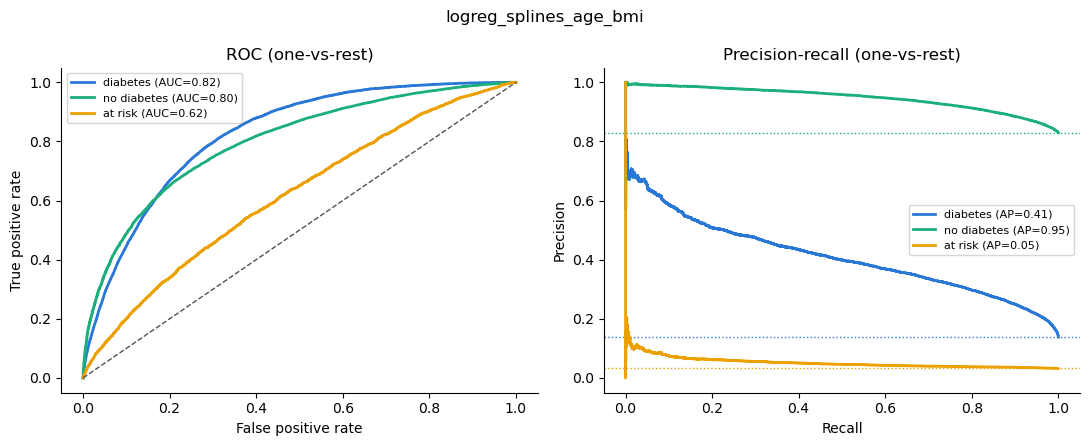

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](3,)","[1.,3.,4.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](28,)","['bmi','poor_physical_health_days','poor_mental_health_days',..., 'cant_afford_doctor','difficulty_walking','sex']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('spline', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``)

In [62]:
from sklearn.preprocessing import SplineTransformer

spline_cols = ["age", "bmi"]
other_numeric_cols = [column for column in numeric_cols if column not in spline_cols]

spline_preprocess = ColumnTransformer([
    ("spline", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("spline", SplineTransformer(n_knots=5, degree=3)),
    ]), spline_cols),
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), other_numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), binary_cols),
])

spline_pipeline = Pipeline([
    ("prep", spline_preprocess),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", C=1.0,
                               solver="lbfgs", random_state=RANDOM_STATE)),
])

spline_config = {"model": "LogisticRegression", "class_weight": "balanced", "C": 1.0,
                 "splines": "age, bmi (5 knots, cubic)"}

log_experiment("logreg_splines_age_bmi", spline_pipeline, spline_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


[xgb_depth4_lr0.05_trees500] SCREENING  sensitivity = 0.831 | precision = 0.298 | F2 = 0.612 | F1 = 0.438 | specificity = 0.597 | flagged = 47.6%
    flagged: diabetes = 0.859 | at risk = 0.709 | diabetics missed = 0.141
    OVERALL  ROC-AUC (OvR) = 0.7545 | macro F1 = 0.4232 | balanced acc = 0.5346 | accuracy = 0.6019
              precision    recall  f1-score   support

    diabetes      0.326     0.697     0.444     11957
 no diabetes      0.945     0.597     0.732     71742
     at risk      0.055     0.309     0.094      2769

    accuracy                          0.602     86468
   macro avg      0.442     0.535     0.423     86468
weighted avg      0.831     0.602     0.672     86468



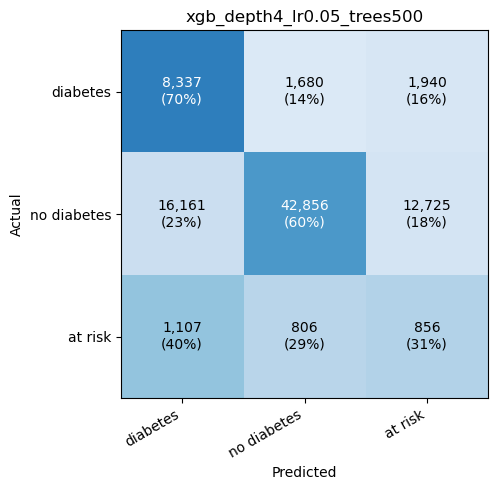

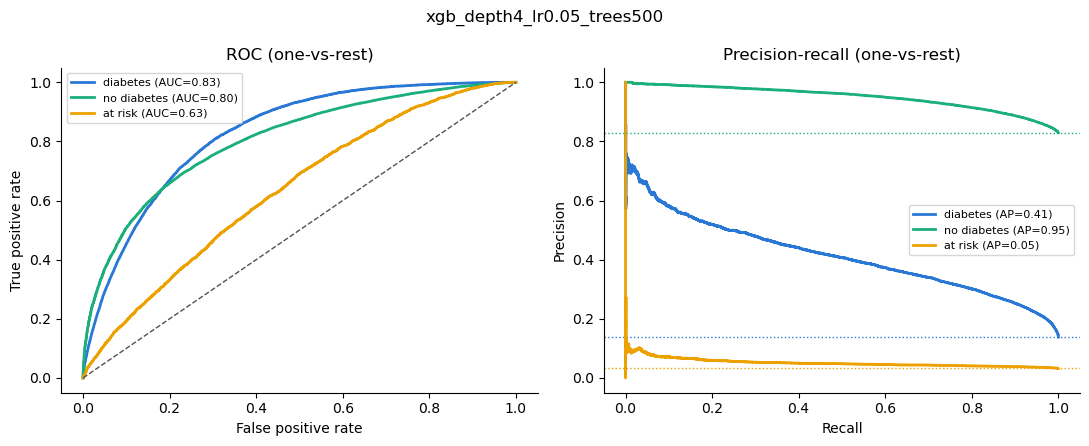

,xgb_params,"{'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 5, ...}"
,use_class_weights,True
Name,Type,Value
booster_model_,XGBClassifier,"XGBClassifier...ree=None, ...)"
classes_,"ndarray[float64](3,)","[1.,3.,4.]"


In [75]:
from xgboost import XGBClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.class_weight import compute_sample_weight


class BalancedXGBClassifier(BaseEstimator, ClassifierMixin):
    """XGBoost with labels 1/3/4 and balanced class weights.
    XGBoost needs labels 0..K-1 and has no class_weight option for multiclass,
    so labels are encoded and balanced sample weights are passed in fit()."""

    def __init__(self, use_class_weights=True, xgb_params=None):
        self.use_class_weights = use_class_weights
        self.xgb_params = xgb_params

    def fit(self, X, y):
        self.classes_ = np.sort(np.unique(y))
        class_to_index = {class_code: class_index for class_index, class_code in enumerate(self.classes_)}
        encoded_labels = np.asarray(pd.Series(np.asarray(y)).map(class_to_index), dtype=int)
        sample_weight = compute_sample_weight("balanced", encoded_labels) if self.use_class_weights else None
        self.booster_model_ = XGBClassifier(**(self.xgb_params or {}))
        self.booster_model_.fit(X, encoded_labels, sample_weight=sample_weight)
        return self

    def predict_proba(self, X):
        return self.booster_model_.predict_proba(X)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

xgb_params = {
    "n_estimators": 500,
    "learning_rate": 0.05,
    "max_depth": 4,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 5,
    "tree_method": "hist",
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}

xgboost_model = BalancedXGBClassifier(xgb_params=xgb_params)

xgboost_config = {"model": "XGBoost", "class_weight": "balanced (sample weights)", **xgb_params}

log_experiment("xgb_depth4_lr0.05_trees500", xgboost_model, xgboost_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


## Deep Neurone Network

In [51]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.base import clone
from sklearn.utils.class_weight import compute_class_weight

I0000 00:00:1792146092.693603  445010 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792146092.695486  445010 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792146093.021715  445010 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792146095.294774  445010 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [52]:
network_preprocess = clone(preprocess)
prepared_train = network_preprocess.fit_transform(X_train)
prepared_val = network_preprocess.transform(X_val)
prepared_test = network_preprocess.transform(X_test)

In [53]:
def to_dense_float32(prepared_matrix):
    if hasattr(prepared_matrix, "toarray"):      # sparse -> dense
        prepared_matrix = prepared_matrix.toarray()
    return np.asarray(prepared_matrix, dtype="float32")

prepared_train = to_dense_float32(prepared_train)
prepared_val = to_dense_float32(prepared_val)
prepared_test = to_dense_float32(prepared_test)

In [54]:
def plot_training_curves(training_history, run_name, metric_names=None, columns_per_row=4):
    """Training vs validation curve for every metric, one small chart per metric.
    The dashed line marks the epoch with the lowest validation loss."""
    if metric_names is None:
        metric_names = [name for name in training_history if not name.startswith("val_")
                        and f"val_{name}" in training_history]
    epochs = np.arange(1, len(training_history["loss"]) + 1)
    best_epoch = int(np.argmin(training_history["val_loss"])) + 1

    row_count = int(np.ceil(len(metric_names) / columns_per_row))
    figure, axes_grid = plt.subplots(row_count, columns_per_row,
                                     figsize=(4 * columns_per_row, 3.2 * row_count), squeeze=False)
    for chart_axis, metric_name in zip(axes_grid.flat, metric_names):
        chart_axis.plot(epochs, training_history[metric_name], color="#2a78d6", linewidth=2, label="training")
        chart_axis.plot(epochs, training_history[f"val_{metric_name}"], color="#eb6834", linewidth=2, label="validation")
        chart_axis.axvline(best_epoch, color="#52514e", linewidth=1, linestyle="--")
        chart_axis.set_title(metric_name.replace("_", " "), fontsize=10)
        chart_axis.set_xlabel("epoch", fontsize=8)
        chart_axis.tick_params(labelsize=8)
        chart_axis.grid(axis="y", color="#e5e5e3", linewidth=0.8)
        chart_axis.set_axisbelow(True)
        for side in ["top", "right"]:
            chart_axis.spines[side].set_visible(False)
    for unused_axis in list(axes_grid.flat)[len(metric_names):]:
        unused_axis.set_visible(False)

    legend_handles, legend_labels = axes_grid.flat[0].get_legend_handles_labels()
    figure.legend(legend_handles + [plt.Line2D([], [], color="#52514e", linestyle="--")],
                  legend_labels + [f"lowest validation loss (epoch {best_epoch})"],
                  loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
    figure.suptitle(f"{run_name}: training vs validation per epoch", y=1.04, fontsize=12)
    figure.tight_layout()
    plt.show()
    return figure

In [55]:
label_to_index = {1: 0, 3: 1, 4: 2}
index_to_label = np.array([1, 3, 4])            # to convert predictions back to the original classes

train_label_indices = Y_train.map(label_to_index).values
val_label_indices = Y_val.map(label_to_index).values

train_labels_one_hot = keras.utils.to_categorical(train_label_indices, num_classes=3)
val_labels_one_hot = keras.utils.to_categorical(val_label_indices, num_classes=3)

In [56]:
train_dataset = (tf.data.Dataset.from_tensor_slices((prepared_train, train_labels_one_hot))
                 .shuffle(buffer_size=len(prepared_train), seed=RANDOM_STATE)
                 .batch(512)
                 .prefetch(tf.data.AUTOTUNE))

# no shuffle: predictions must stay in the same order as Y_val
val_dataset = (tf.data.Dataset.from_tensor_slices((prepared_val, val_labels_one_hot))
               .batch(512)
               .prefetch(tf.data.AUTOTUNE))

E0000 00:00:1792146156.645757  445010 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792146156.646432  448086 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1792146156.670475  445010 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [57]:
def build_network(
        n_features=prepared_train.shape[1],
        hidden_units=(256, 128, 64, 64),
        dropout_rate=0.0,
        l2=0.0,
        learning_rate=1e-3,
        ):
    """Builds a dense network for the 3-class target (softmax output) and its Adam optimizer.
    hidden_units sets the capacity: one Dense layer per entry, the entry is the layer width."""

    weight_regularizer = keras.regularizers.l2(l2) if l2 > 0 else None
    optimizer=keras.optimizers.Adam(learning_rate=learning_rate)
    inputs = keras.Input(shape=(n_features,), name="Features")
    x = inputs

    for layer_number, layer_width in enumerate(hidden_units, start=1):
        x = layers.Dense(
            layer_width,
            kernel_regularizer=weight_regularizer,
            activation="relu",
            use_bias=True,
            name=f"dense_{layer_number}",
        )(x)
        if dropout_rate > 0:
            x = layers.Dropout(dropout_rate, name=f"dropout_{layer_number}")(x)

    outputs = layers.Dense(3, activation="softmax", name="output")(x)

    model = keras.Model(inputs, outputs, name="tabular_net")
    return model, optimizer

In [59]:
def keras_metrics():
    metric_list = [
        "accuracy",
        keras.metrics.AUC(name="auc", multi_label=True, num_labels=3),        # one-vs-rest AUC, averaged
        keras.metrics.AUC(name="pr_auc", curve="PR", multi_label=True, num_labels=3),
        keras.metrics.F1Score(name="f1_macro", average="macro"),
        keras.metrics.FBetaScore(name="f2_macro", beta=2.0, average="macro")
        ]

    class_index_names = {0: "diabetes", 1: "no_diabetes", 2: "at_risk"}
    

    for class_index, class_name in class_index_names.items():
        metric_list.append(keras.metrics.Precision(class_id=class_index, top_k=1, name=f"precision_{class_name}"))   # top_k=1: highest-probability class, as in the classical models
        metric_list.append(keras.metrics.Recall(class_id=class_index, top_k=1, name=f"recall_{class_name}"))
    return metric_list


In [90]:
def compiled_network(network_model, metrics, loss="categorical_crossentropy"):
    net_model, optimizer = network_model
    model = net_model
    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=metrics)
    return model

# test model
model = compiled_network(network_model=build_network(), metrics=keras_metrics())
model.summary()

Model: "tabular_net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Features (InputLayer)           │ (None, 59)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        15,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,867 (237.76 KB)

 Trainable params: 60,867 (237.76 KB)

 Non-trainable params: 0 (0.00 B)

In [61]:
# Balanced class weights, the same imbalance handling as the classical models
class_weight_values = compute_class_weight("balanced", classes=np.arange(3), y=train_label_indices)
class_weight = {class_index: float(weight) for class_index, weight in enumerate(class_weight_values)}
print("class weights:", class_weight)


def train_network(network, run_name, epochs=30, extra_callbacks=None):
    """Trains a freshly built network and logs it to its own TensorBoard folder.
    Always pass a newly built model: calling fit on the same model again continues from its old weights."""
    tensorboard_callback = keras.callbacks.TensorBoard(log_dir=os.path.join(LOG_DIR, run_name))
    return network.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=epochs,
        class_weight=class_weight,
        callbacks=[tensorboard_callback] + list(extra_callbacks or []),
        verbose=2,                      # one line per epoch
    )

class weights: {0: 2.410450118941421, 1: 0.4017584861593169, 2: 10.40775958915102}


In [63]:
from sklearn.base import BaseEstimator, ClassifierMixin


class TrainedNetworkAdapter(BaseEstimator, ClassifierMixin):
    """Wraps an already trained Keras network so log_experiment can evaluate it like the classical models.
    fit() does nothing (the network is already trained); predictions use the highest-probability class.
    Use with do_cv=False: there is nothing to cross-validate because fit() does not train."""

    def __init__(self, network):
        self.network = network

    def fit(self, X, y):
        self.classes_ = index_to_label                      # [1, 3, 4], the original class codes
        return self

    def predict_proba(self, X):
        prepared_features = to_dense_float32(network_preprocess.transform(X))
        return self.network.predict(prepared_features, batch_size=512, verbose=0)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

In [64]:
# Baseline: no early stopping and no learning-rate schedule, to see whether it overfits
history = train_network(model, run_name="baseline_neurone_network", epochs=30)

Epoch 1/30


E0000 00:00:1792146208.936431  445010 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


507/507 - 14s - 27ms/step - accuracy: 0.5811 - auc: 0.7435 - f1_macro: 0.4115 - f2_macro: 0.4465 - loss: 0.9513 - pr_auc: 0.4648 - precision_at_risk: 0.0516 - precision_diabetes: 0.3135 - precision_no_diabetes: 0.9444 - recall_at_risk: 0.2981 - recall_diabetes: 0.7120 - recall_no_diabetes: 0.5702 - val_accuracy: 0.6088 - val_auc: 0.7481 - val_f1_macro: 0.4240 - val_f2_macro: 0.4595 - val_loss: 0.8713 - val_pr_auc: 0.4715 - val_precision_at_risk: 0.0543 - val_precision_diabetes: 0.3236 - val_precision_no_diabetes: 0.9406 - val_recall_at_risk: 0.2723 - val_recall_diabetes: 0.7185 - val_recall_no_diabetes: 0.6035
Epoch 2/30
507/507 - 9s - 18ms/step - accuracy: 0.5926 - auc: 0.7563 - f1_macro: 0.4202 - f2_macro: 0.4578 - loss: 0.9360 - pr_auc: 0.4719 - precision_at_risk: 0.0574 - precision_diabetes: 0.3204 - precision_no_diabetes: 0.9436 - recall_at_risk: 0.3175 - recall_diabetes: 0.7208 - recall_no_diabetes: 0.5818 - val_accuracy: 0.6313 - val_auc: 0.7514 - val_f1_macro: 0.4304 - val_f2_m

In [65]:
model.evaluate(val_dataset)

169/169 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6043 - auc: 0.6991 - f1_macro: 0.4060 - f2_macro: 0.4333 - loss: 0.9069 - pr_auc: 0.4466 - precision_at_risk: 0.0427 - precision_diabetes: 0.2967 - precision_no_diabetes: 0.9353 - recall_at_risk: 0.2037 - recall_diabetes: 0.6534 - recall_no_diabetes: 0.6115


[0.906948983669281,
 0.604269802570343,
 0.699063777923584,
 0.44658657908439636,
 0.4060405194759369,
 0.43327203392982483,
 0.29665490984916687,
 0.6534247994422913,
 0.9352589845657349,
 0.6115385890007019,
 0.04265940561890602,
 0.20368364453315735]

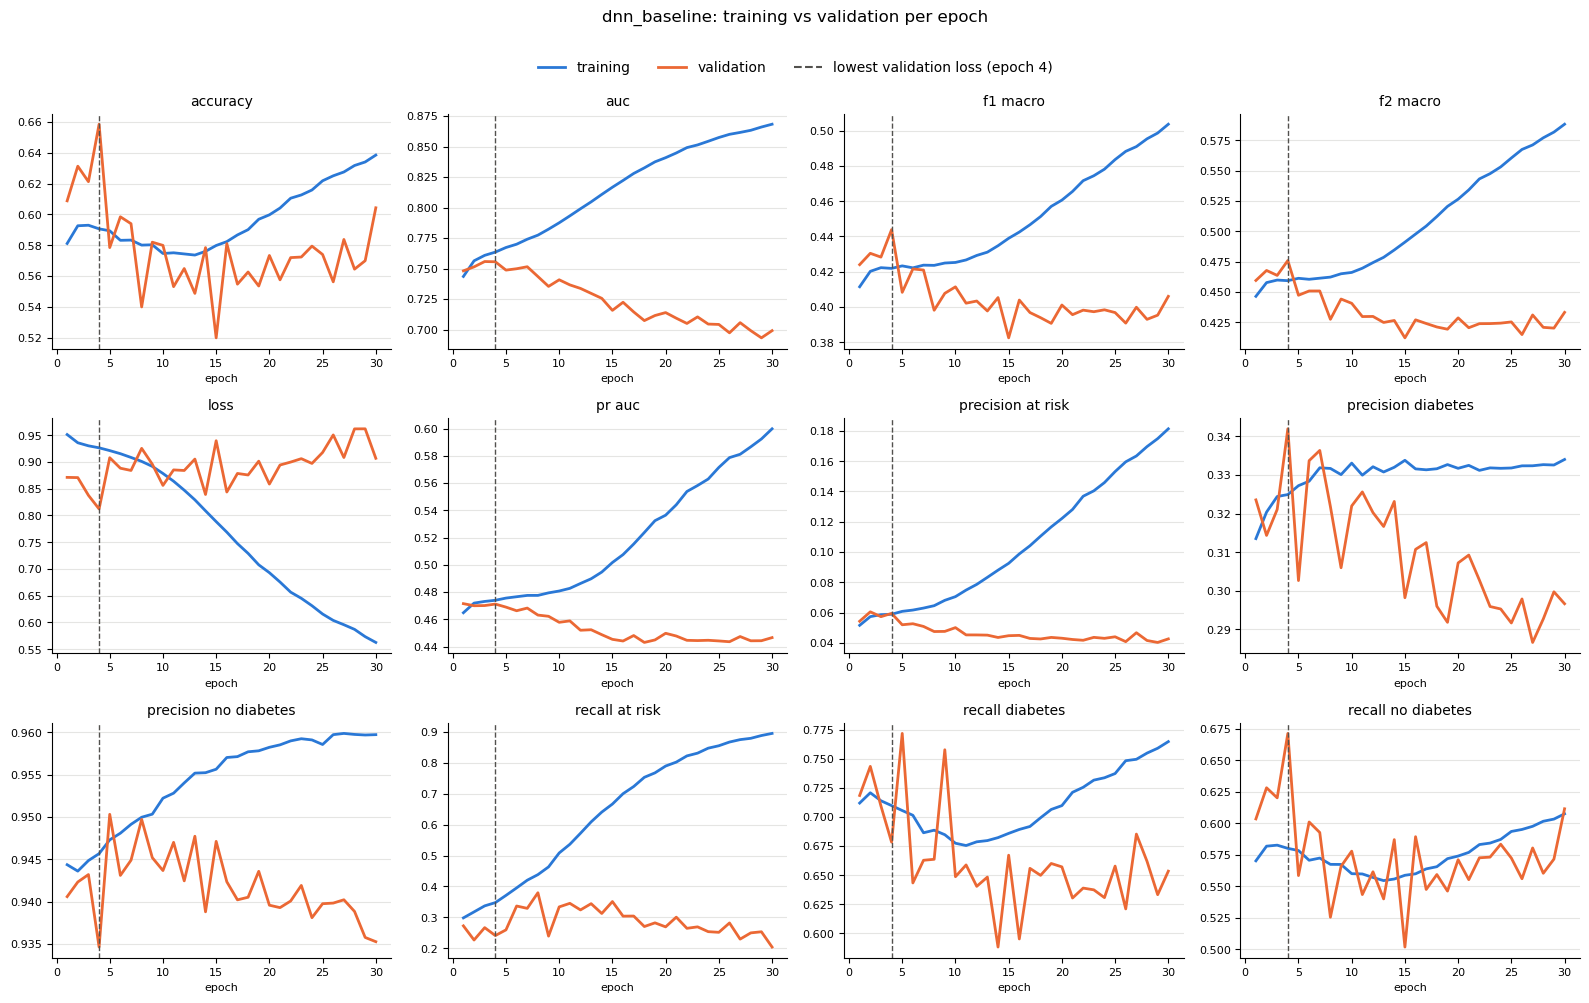

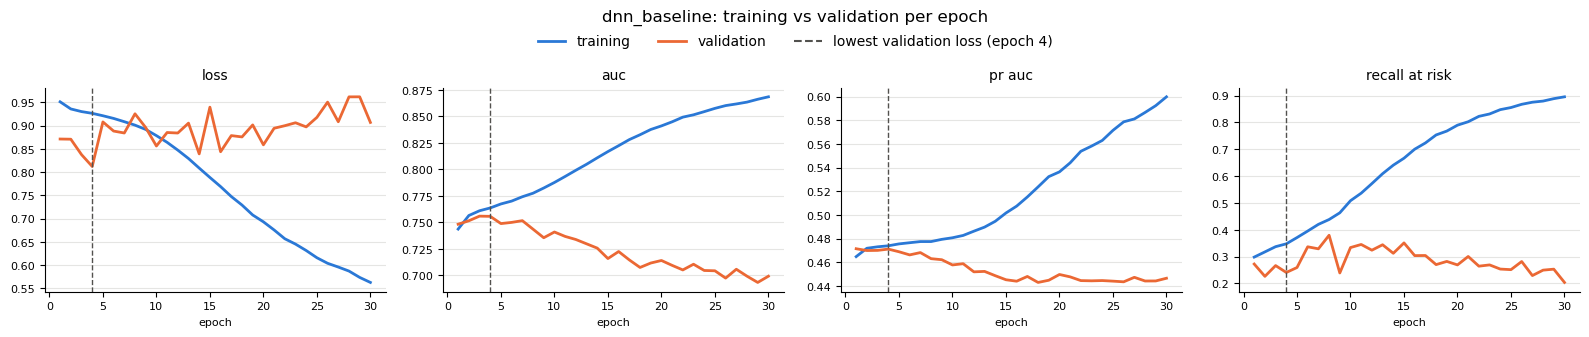

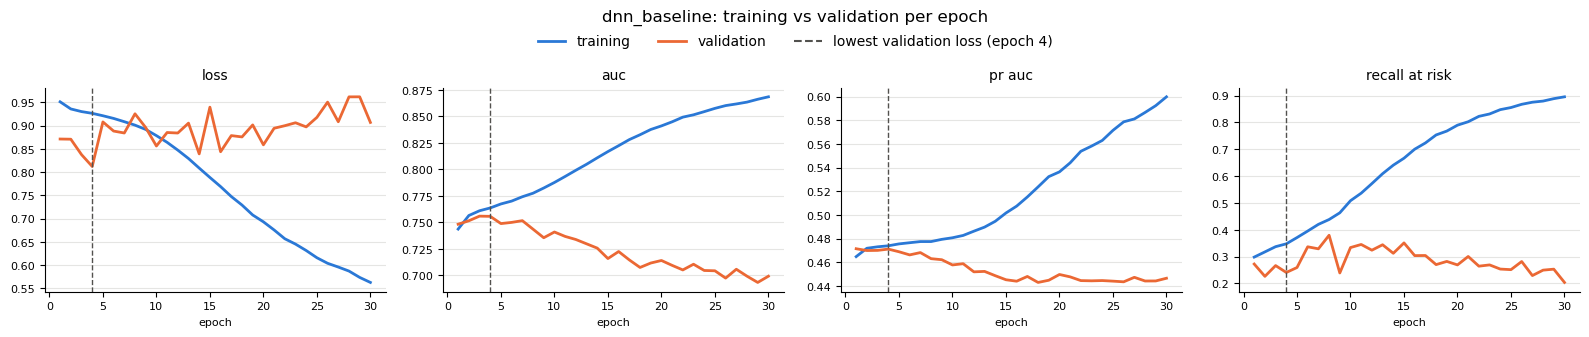

In [66]:
plot_training_curves(history.history, "dnn_baseline")
plot_training_curves(history.history, "dnn_baseline",
                     metric_names=["loss", "auc", "pr_auc", "recall_at_risk"])


[baseline_neurone_network] SCREENING  sensitivity = 0.794 | precision = 0.295 | F2 = 0.594 | F1 = 0.431 | specificity = 0.612 | flagged = 45.7%
    flagged: diabetes = 0.832 | at risk = 0.629 | diabetics missed = 0.168
    OVERALL  ROC-AUC (OvR) = 0.7039 | macro F1 = 0.4060 | balanced acc = 0.4895 | accuracy = 0.6043
              precision    recall  f1-score   support

    diabetes      0.297     0.653     0.408     11957
 no diabetes      0.935     0.612     0.740     71742
     at risk      0.043     0.204     0.071      2769

    accuracy                          0.604     86468
   macro avg      0.425     0.490     0.406     86468
weighted avg      0.818     0.604     0.672     86468



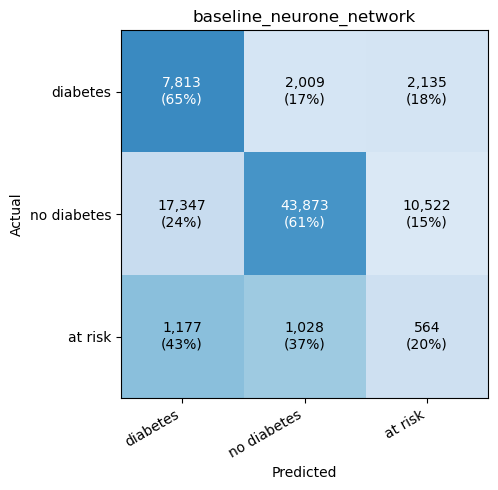

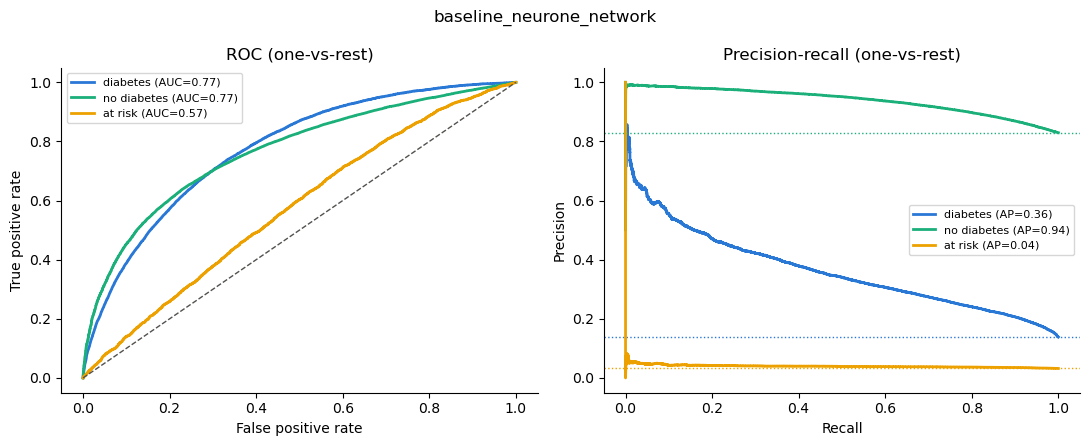

,network,"<Functional n...t, built=True>"
Name,Type,Value
classes_,"ndarray[int64](3,)","[1,3,4]"


In [67]:
# Same metrics, plots, TensorBoard logging and results-table row as the classical models
dnn_config = {"model": "Keras MLP", "hidden_units": "256-128-64-64", "dropout_rate": 0.0,
              "learning_rate": 1e-3, "epochs": 30, "class_weight": "balanced", "scheduler": "none"}

log_experiment("baseline_neurone_network", TrainedNetworkAdapter(model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)

The previous run shows many signs of overfitting. The training metrics keep improving for all 30 epochs. For example, loss started at 0.95 and ended at 0.54, and AUC started at 0.75 and ended at 0.87, while the validation metrics peak at epoch 4, and then get worse- validation loss rises from 0.81 to 0.91, AUC falls from 0.757 to 0.704. The other sign can be seen between training recall on at risk (0.88), and validation recall at risk 0.1380 at epoch 30. The gap between them keeps widening. So the network is memorizing the training data instead of learning patterns that generalize.

## Add regularization:Dropout and L2

In [68]:
dropout_model = compiled_network(network_model=build_network(dropout_rate=0.3), metrics=keras_metrics())
dropout_history = train_network(dropout_model, run_name="dnn_dropout0.3", epochs=30)

Epoch 1/30
507/507 - 16s - 31ms/step - accuracy: 0.5612 - auc: 0.7187 - f1_macro: 0.3968 - f2_macro: 0.4277 - loss: 0.9841 - pr_auc: 0.4482 - precision_at_risk: 0.0467 - precision_diabetes: 0.2989 - precision_no_diabetes: 0.9383 - recall_at_risk: 0.2908 - recall_diabetes: 0.6733 - recall_no_diabetes: 0.5530 - val_accuracy: 0.6206 - val_auc: 0.7486 - val_f1_macro: 0.4264 - val_f2_macro: 0.4614 - val_loss: 0.8775 - val_pr_auc: 0.4705 - val_precision_at_risk: 0.0518 - val_precision_diabetes: 0.3234 - val_precision_no_diabetes: 0.9425 - val_recall_at_risk: 0.2326 - val_recall_diabetes: 0.7324 - val_recall_no_diabetes: 0.6170
Epoch 2/30
507/507 - 11s - 21ms/step - accuracy: 0.5855 - auc: 0.7420 - f1_macro: 0.4140 - f2_macro: 0.4502 - loss: 0.9577 - pr_auc: 0.4610 - precision_at_risk: 0.0540 - precision_diabetes: 0.3134 - precision_no_diabetes: 0.9435 - recall_at_risk: 0.3003 - recall_diabetes: 0.7174 - recall_no_diabetes: 0.5745 - val_accuracy: 0.5841 - val_auc: 0.7429 - val_f1_macro: 0.410

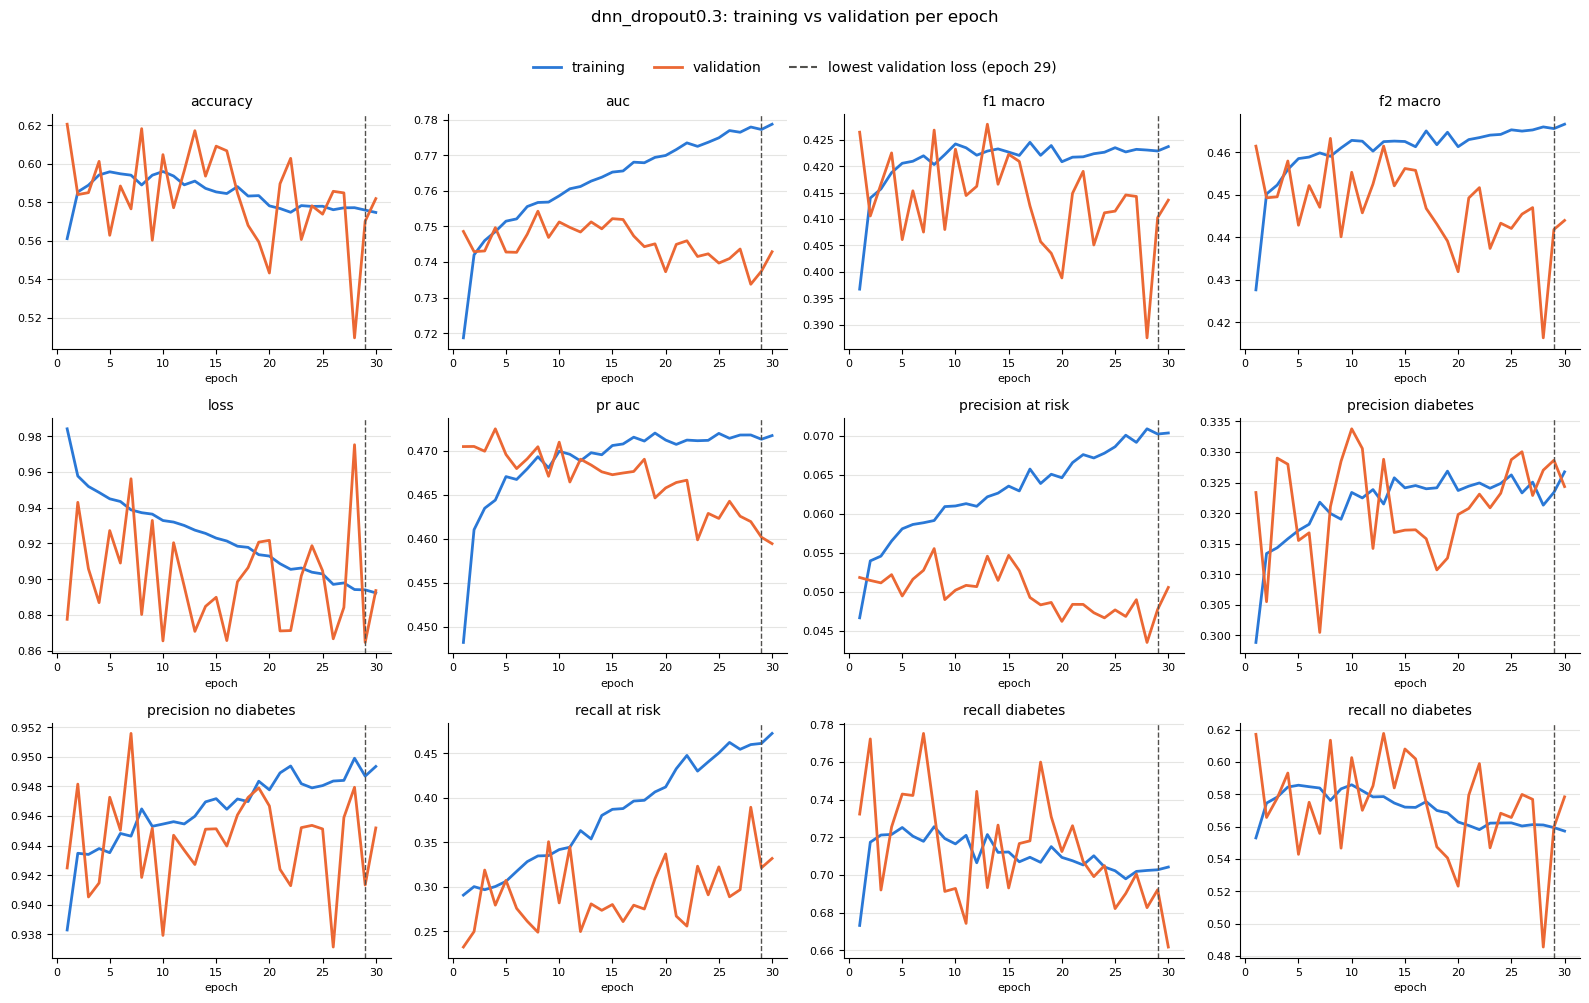

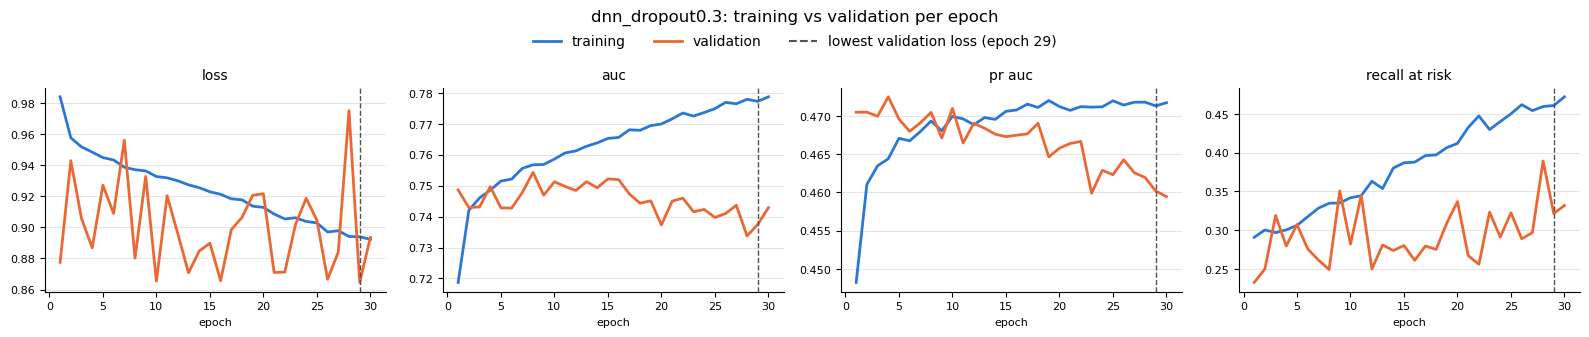

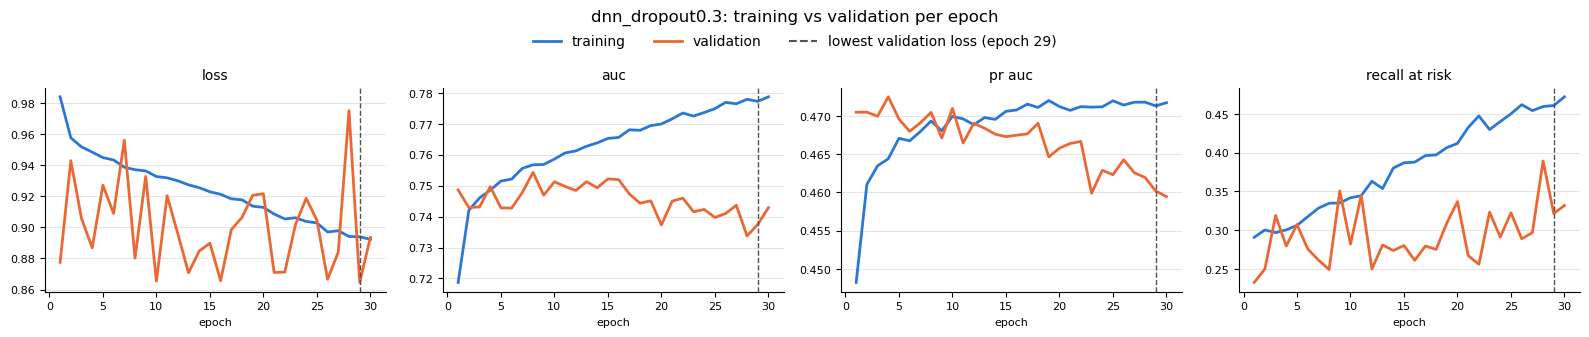

In [69]:
plot_training_curves(dropout_history.history, "dnn_dropout0.3")
plot_training_curves(dropout_history.history, "dnn_dropout0.3",
                     metric_names=["loss", "auc", "pr_auc", "recall_at_risk"])


[dnn_dropout0.3] SCREENING  sensitivity = 0.837 | precision = 0.289 | F2 = 0.607 | F1 = 0.430 | specificity = 0.578 | flagged = 49.2%
    flagged: diabetes = 0.867 | at risk = 0.705 | diabetics missed = 0.133
    OVERALL  ROC-AUC (OvR) = 0.7429 | macro F1 = 0.4136 | balanced acc = 0.5240 | accuracy = 0.5820
              precision    recall  f1-score   support

    diabetes      0.324     0.662     0.435     11957
 no diabetes      0.945     0.578     0.718     71742
     at risk      0.051     0.332     0.088      2769

    accuracy                          0.582     86468
   macro avg      0.440     0.524     0.414     86468
weighted avg      0.831     0.582     0.658     86468



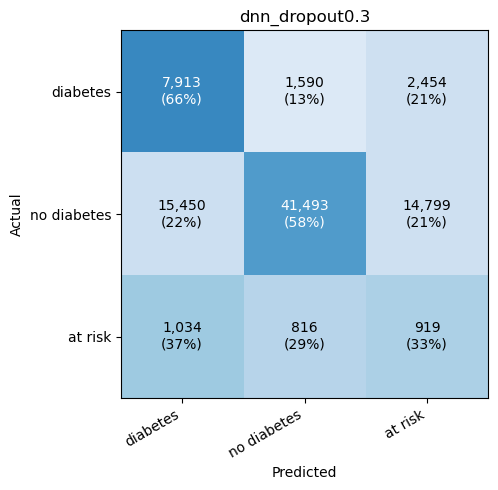

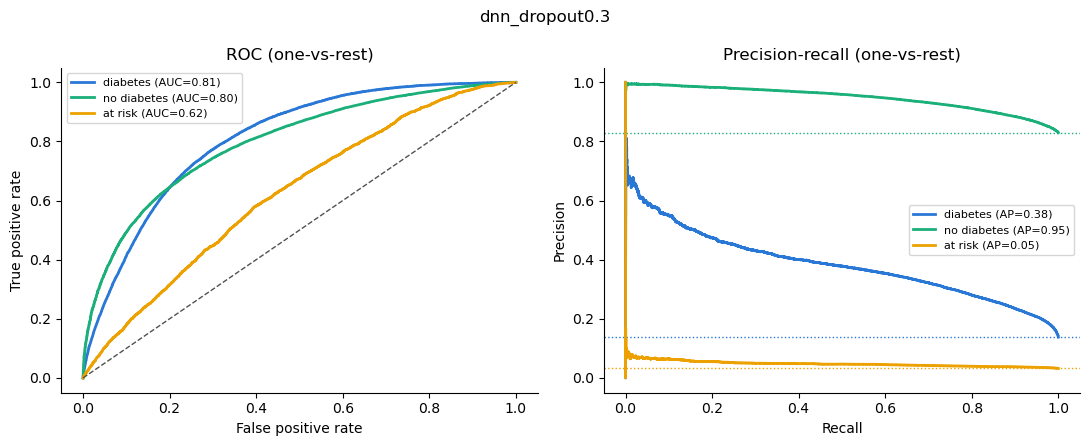

,network,"<Functional n...t, built=True>"
Name,Type,Value
classes_,"ndarray[int64](3,)","[1,3,4]"


In [70]:
# Same metrics, plots, TensorBoard logging and results-table row as the classical models
dnn_config = {"model": "Keras MLP", "hidden_units": "256-128-64-64", "dropout_rate": 0.3,
              "learning_rate": 1e-3, "epochs": 30, "class_weight": "balanced", "scheduler": "none"}

log_experiment("dnn_dropout0.3", TrainedNetworkAdapter(dropout_model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)

The dropout helped reduce some overfitting noticed in experiment 1. However,the loss on validation set shows various instabilities, suggesting that the same learning rate used from start to finish might be higher after a number of epoch. The next run will introduce ReduceLROnPlateau to halve the learning rate when the validation loss stops improving

In [71]:
dropout_scheduler_model = compiled_network(network_model=build_network(dropout_rate=0.3), metrics=keras_metrics())

reduce_learning_rate = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1,
)
dropout_scheduler_history = train_network(dropout_scheduler_model, run_name="dnn_dropout0.3_reduce_lr",
                                          epochs=30, extra_callbacks=[reduce_learning_rate])

Epoch 1/30
507/507 - 15s - 30ms/step - accuracy: 0.5818 - auc: 0.7221 - f1_macro: 0.4045 - f2_macro: 0.4375 - loss: 0.9807 - pr_auc: 0.4506 - precision_at_risk: 0.0481 - precision_diabetes: 0.2997 - precision_no_diabetes: 0.9384 - recall_at_risk: 0.2530 - recall_diabetes: 0.7010 - recall_no_diabetes: 0.5746 - val_accuracy: 0.6393 - val_auc: 0.7523 - val_f1_macro: 0.4320 - val_f2_macro: 0.4680 - val_loss: 0.8669 - val_pr_auc: 0.4716 - val_precision_at_risk: 0.0560 - val_precision_diabetes: 0.3204 - val_precision_no_diabetes: 0.9395 - val_recall_at_risk: 0.1979 - val_recall_diabetes: 0.7491 - val_recall_no_diabetes: 0.6381 - learning_rate: 0.0010
Epoch 2/30
507/507 - 11s - 21ms/step - accuracy: 0.5910 - auc: 0.7423 - f1_macro: 0.4142 - f2_macro: 0.4518 - loss: 0.9569 - pr_auc: 0.4616 - precision_at_risk: 0.0542 - precision_diabetes: 0.3079 - precision_no_diabetes: 0.9442 - recall_at_risk: 0.2688 - recall_diabetes: 0.7413 - recall_no_diabetes: 0.5784 - val_accuracy: 0.6202 - val_auc: 0.75

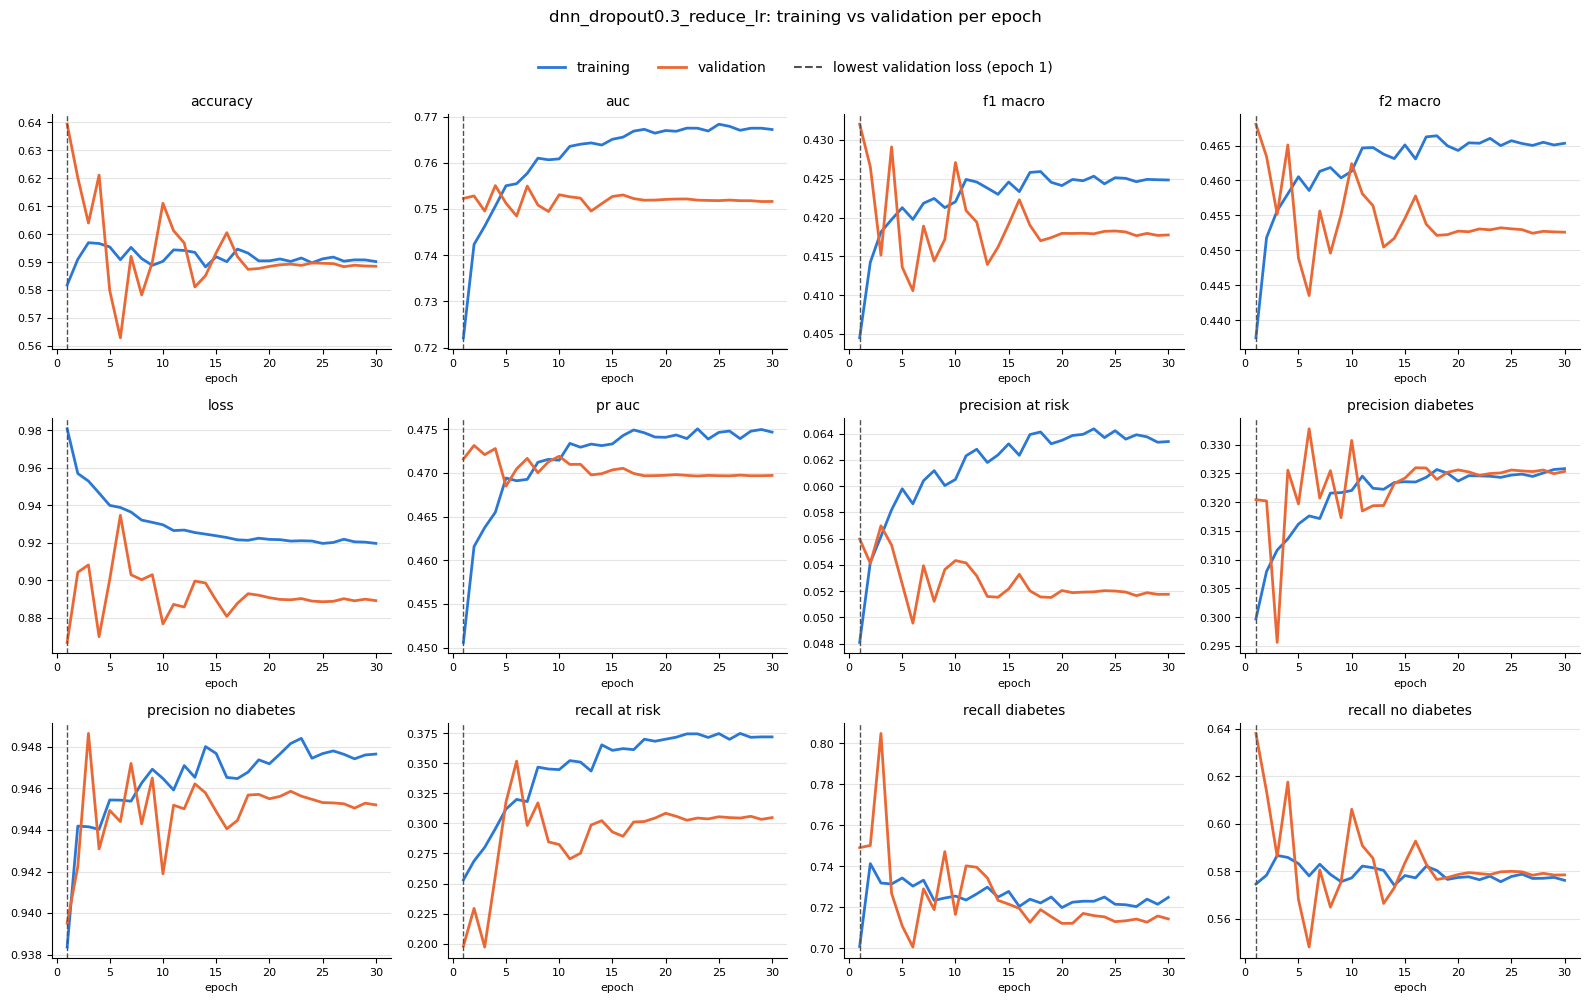

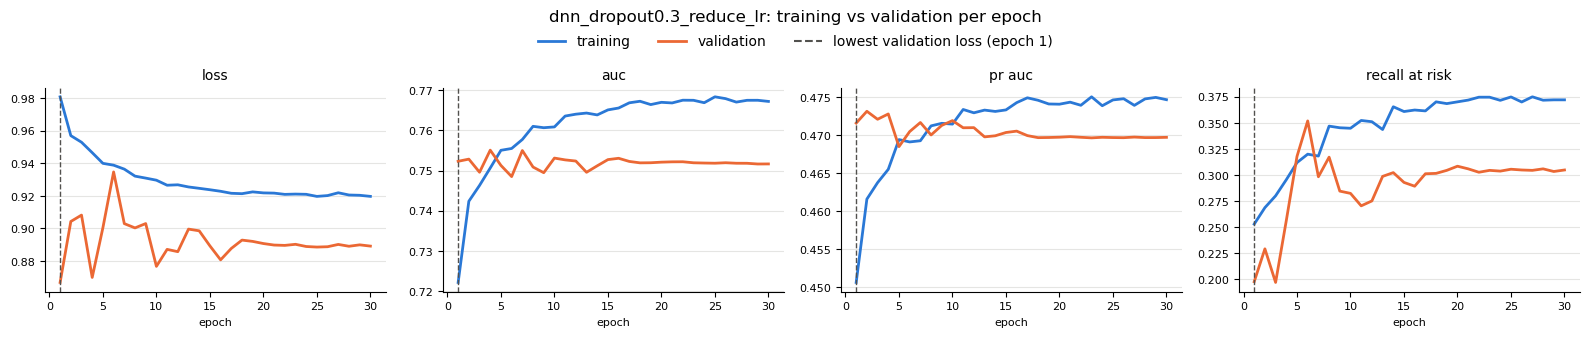

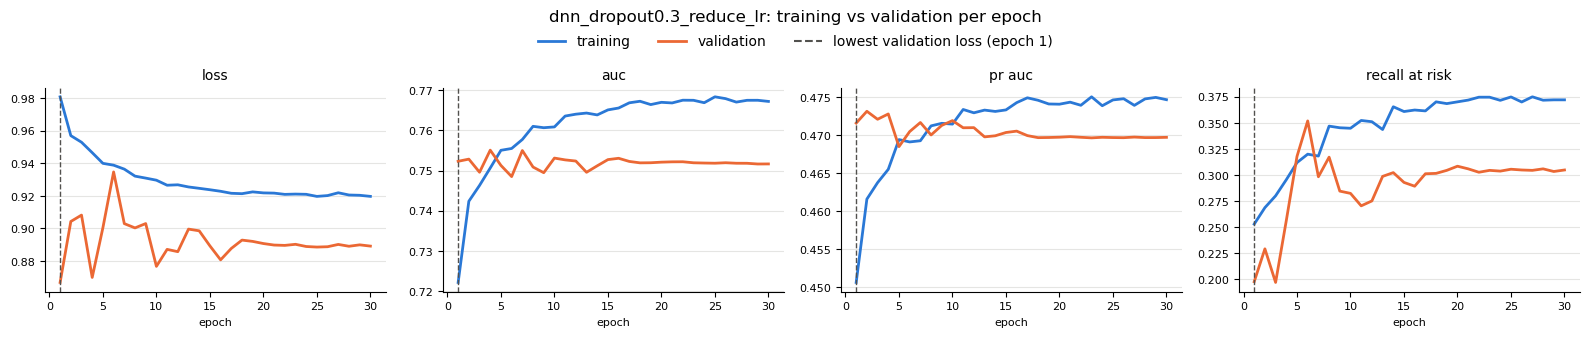

In [72]:
plot_training_curves(dropout_scheduler_history.history, "dnn_dropout0.3_reduce_lr")
plot_training_curves(dropout_scheduler_history.history, "dnn_dropout0.3_reduce_lr",
                     metric_names=["loss", "auc", "pr_auc", "recall_at_risk"])


[dnn_dropout0.3_reduce_lr] SCREENING  sensitivity = 0.837 | precision = 0.289 | F2 = 0.607 | F1 = 0.430 | specificity = 0.578 | flagged = 49.2%
    flagged: diabetes = 0.863 | at risk = 0.723 | diabetics missed = 0.137
    OVERALL  ROC-AUC (OvR) = 0.7517 | macro F1 = 0.4178 | balanced acc = 0.5326 | accuracy = 0.5885
              precision    recall  f1-score   support

    diabetes      0.325     0.714     0.447     11957
 no diabetes      0.945     0.578     0.718     71742
     at risk      0.052     0.305     0.089      2769

    accuracy                          0.589     86468
   macro avg      0.441     0.533     0.418     86468
weighted avg      0.831     0.589     0.660     86468



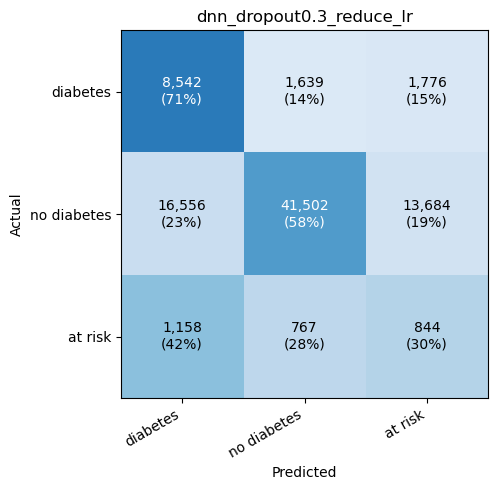

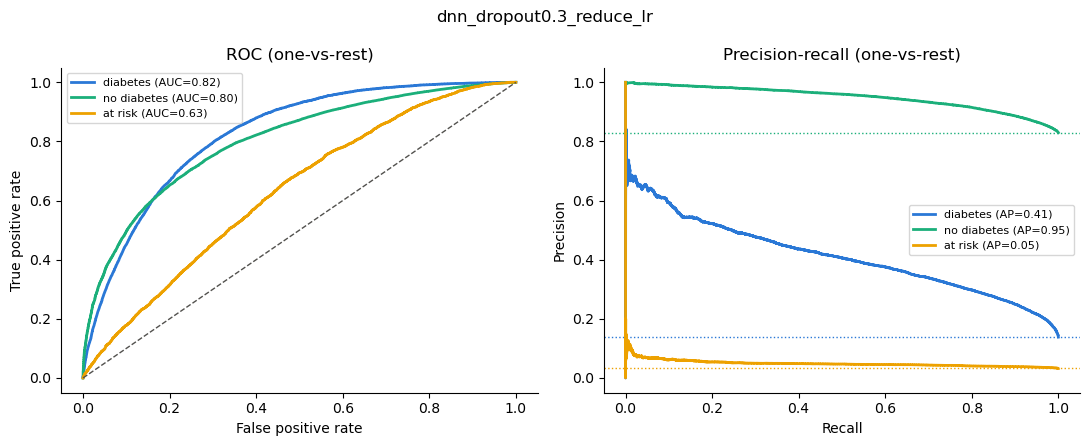

,network,"<Functional n...t, built=True>"
Name,Type,Value
classes_,"ndarray[int64](3,)","[1,3,4]"


In [73]:
# Same metrics, plots, TensorBoard logging and results-table row as the classical models
dnn_config = {"model": "Keras MLP", "hidden_units": "256-128-64-64", "dropout_rate": 0.3,
              "learning_rate": 1e-3, "epochs": 30, "class_weight": "balanced",
              "scheduler": "ReduceLROnPlateau(val_loss, factor 0.5, patience 3, min_lr 1e-5)"}

log_experiment("dnn_dropout0.3_reduce_lr", TrainedNetworkAdapter(dropout_scheduler_model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)

In [74]:
dropout_scheduler_model = compiled_network(network_model=build_network(dropout_rate=0.3), metrics=keras_metrics())

reduce_learning_rate = ReduceLROnPlateau(
    monitor="val_pr_auc",
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1,
)
dropout_scheduler_history = train_network(dropout_scheduler_model, run_name="dnn_dropout0.3_reduce_lr_val_pr_auc",
                                          epochs=30, extra_callbacks=[reduce_learning_rate])


Epoch 1/30
507/507 - 17s - 33ms/step - accuracy: 0.5650 - auc: 0.7175 - f1_macro: 0.3982 - f2_macro: 0.4299 - loss: 0.9860 - pr_auc: 0.4481 - precision_at_risk: 0.0472 - precision_diabetes: 0.2983 - precision_no_diabetes: 0.9379 - recall_at_risk: 0.2827 - recall_diabetes: 0.6816 - recall_no_diabetes: 0.5565 - val_accuracy: 0.6165 - val_auc: 0.7519 - val_f1_macro: 0.4247 - val_f2_macro: 0.4624 - val_loss: 0.9013 - val_pr_auc: 0.4725 - val_precision_at_risk: 0.0567 - val_precision_diabetes: 0.3136 - val_precision_no_diabetes: 0.9438 - val_recall_at_risk: 0.2376 - val_recall_diabetes: 0.7498 - val_recall_no_diabetes: 0.6089 - learning_rate: 0.0010
Epoch 2/30
507/507 - 11s - 22ms/step - accuracy: 0.5815 - auc: 0.7402 - f1_macro: 0.4110 - f2_macro: 0.4471 - loss: 0.9589 - pr_auc: 0.4611 - precision_at_risk: 0.0514 - precision_diabetes: 0.3114 - precision_no_diabetes: 0.9444 - recall_at_risk: 0.2837 - recall_diabetes: 0.7292 - recall_no_diabetes: 0.5683 - val_accuracy: 0.5872 - val_auc: 0.74

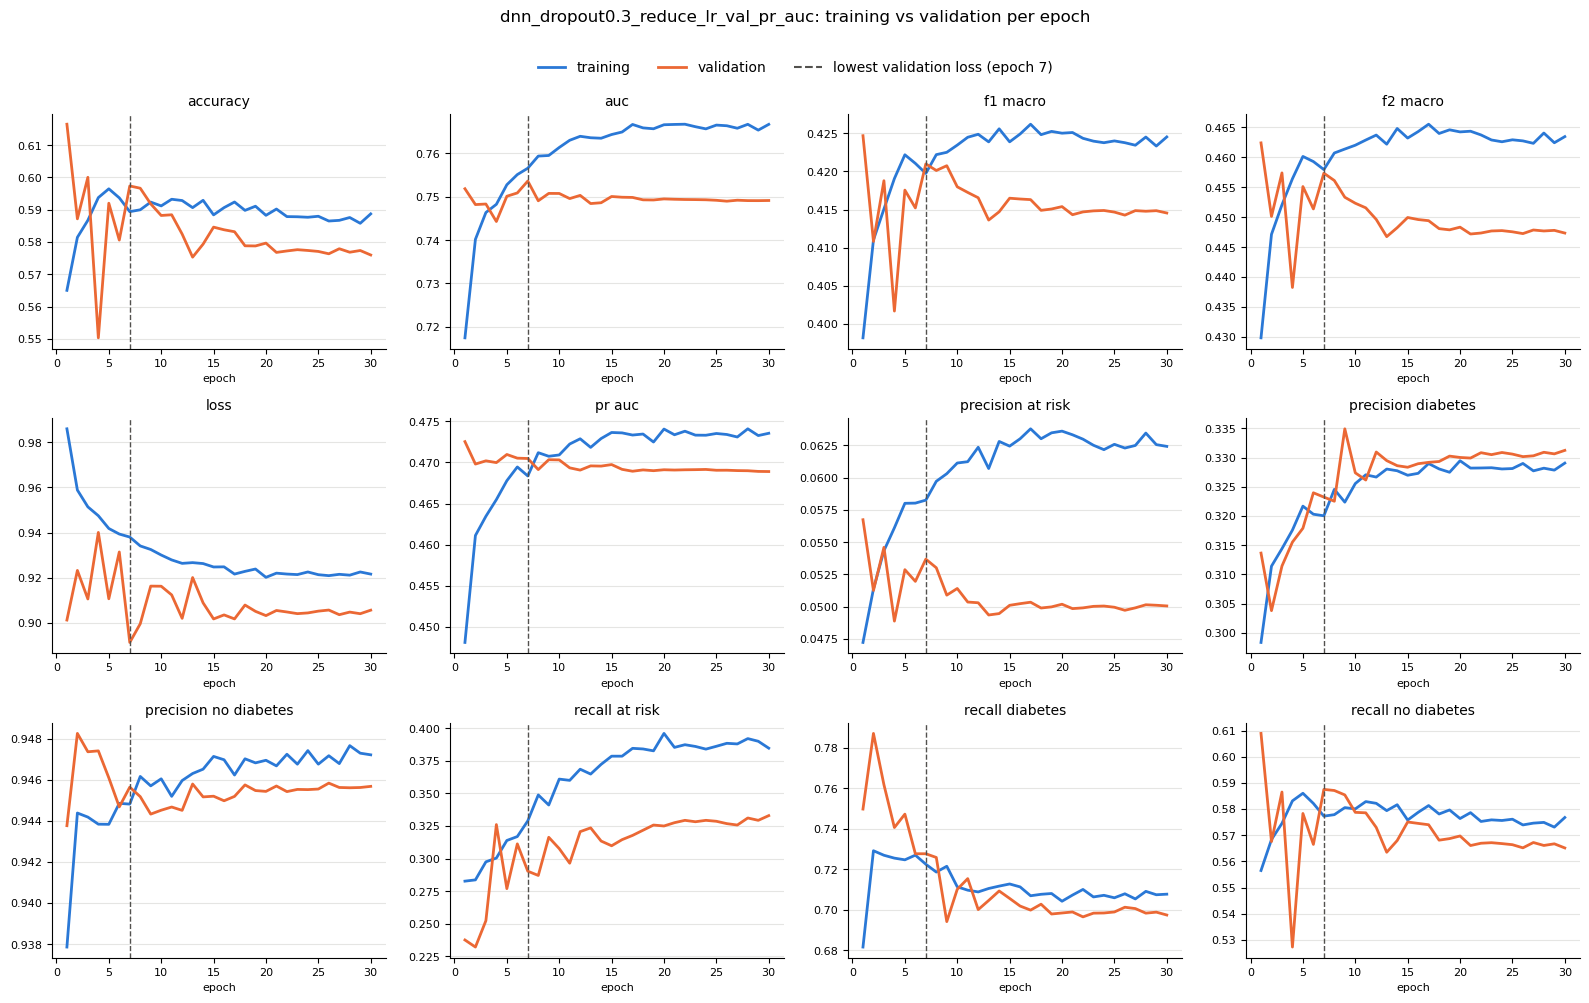

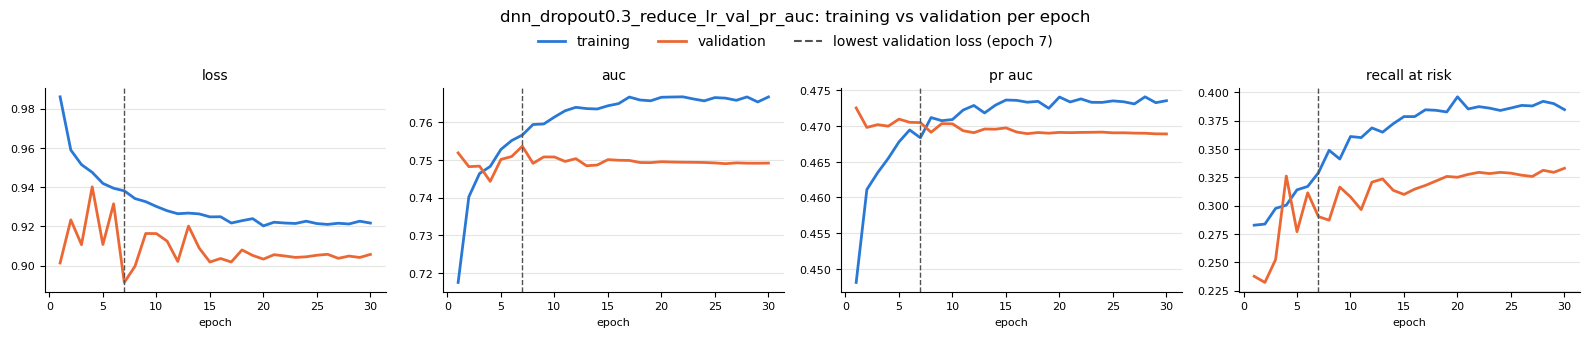

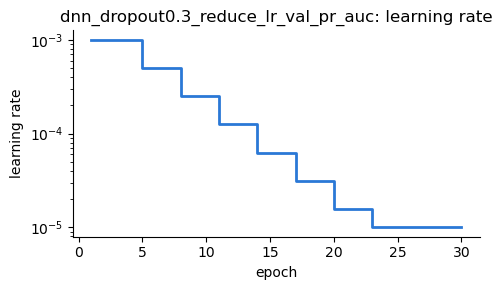

In [75]:
pr_auc_scheduler_history = dropout_scheduler_history   # the val_pr_auc run was stored under this name

plot_training_curves(pr_auc_scheduler_history.history, "dnn_dropout0.3_reduce_lr_val_pr_auc")
plot_training_curves(pr_auc_scheduler_history.history, "dnn_dropout0.3_reduce_lr_val_pr_auc",
                     metric_names=["loss", "auc", "pr_auc", "recall_at_risk"])

learning_rate_values = pr_auc_scheduler_history.history["learning_rate"]
learning_rate_figure, learning_rate_axis = plt.subplots(figsize=(5, 3))
learning_rate_axis.plot(range(1, len(learning_rate_values) + 1), learning_rate_values,
                        color="#2a78d6", linewidth=2, drawstyle="steps-post")
learning_rate_axis.set(xlabel="epoch", ylabel="learning rate",
                       title="dnn_dropout0.3_reduce_lr_val_pr_auc: learning rate")
learning_rate_axis.set_yscale("log")
for side in ["top", "right"]:
    learning_rate_axis.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


[dnn_dropout0.3_reduce_lr_val_pr_auc] SCREENING  sensitivity = 0.842 | precision = 0.284 | F2 = 0.605 | F1 = 0.425 | specificity = 0.565 | flagged = 50.4%
    flagged: diabetes = 0.869 | at risk = 0.723 | diabetics missed = 0.131
    OVERALL  ROC-AUC (OvR) = 0.7491 | macro F1 = 0.4146 | balanced acc = 0.5318 | accuracy = 0.5760
              precision    recall  f1-score   support

    diabetes      0.331     0.697     0.449     11957
 no diabetes      0.946     0.565     0.707     71742
     at risk      0.050     0.333     0.087      2769

    accuracy                          0.576     86468
   macro avg      0.442     0.532     0.415     86468
weighted avg      0.832     0.576     0.652     86468



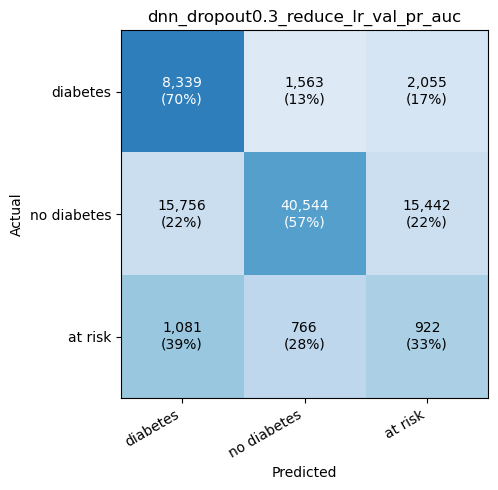

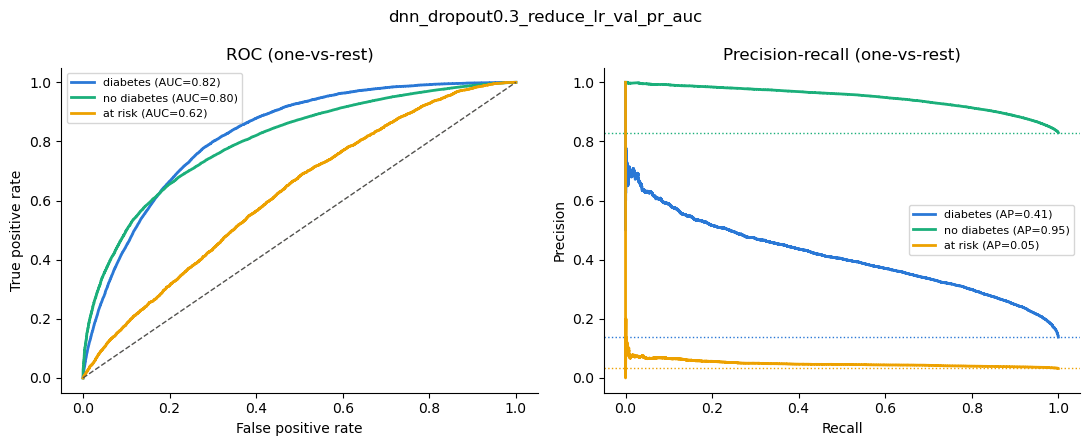

,network,"<Functional n...t, built=True>"
Name,Type,Value
classes_,"ndarray[int64](3,)","[1,3,4]"


In [76]:
# Same metrics, plots, TensorBoard logging and results-table row as the classical models
dnn_config = {"model": "Keras MLP", "hidden_units": "256-128-64-64", "dropout_rate": 0.3,
              "learning_rate": 1e-3, "epochs": 30, "class_weight": "balanced",
              "scheduler": "ReduceLROnPlateau(val_pr_auc, max, factor 0.5, patience 3, min_lr 1e-5)"}

log_experiment("dnn_dropout0.3_reduce_lr_val_pr_auc", TrainedNetworkAdapter(dropout_scheduler_model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)

Add Early stopping on the best performing NN model so far

In [80]:
early_stopping_model = compiled_network(network_model=build_network(dropout_rate=0.3), metrics=keras_metrics())

reduce_learning_rate = ReduceLROnPlateau(          # same scheduler as dnn_dropout0.3_reduce_lr
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1,
)
early_stopping = EarlyStopping(                    # the only change
    monitor="val_pr_auc",
    mode="max",
    patience=10,                                    # more patient than the scheduler (3)
    restore_best_weights=True,
    verbose=1,
)
early_stopping_history = train_network(early_stopping_model, run_name="dnn_dropout0.3_reduce_lr_early_stopping",
                                       epochs=60, extra_callbacks=[reduce_learning_rate, early_stopping])


Epoch 1/60
507/507 - 15s - 29ms/step - accuracy: 0.5617 - auc: 0.7171 - f1_macro: 0.3962 - f2_macro: 0.4266 - loss: 0.9865 - pr_auc: 0.4462 - precision_at_risk: 0.0456 - precision_diabetes: 0.2985 - precision_no_diabetes: 0.9385 - recall_at_risk: 0.2823 - recall_diabetes: 0.6732 - recall_no_diabetes: 0.5539 - val_accuracy: 0.6069 - val_auc: 0.7496 - val_f1_macro: 0.4215 - val_f2_macro: 0.4566 - val_loss: 0.8883 - val_pr_auc: 0.4709 - val_precision_at_risk: 0.0516 - val_precision_diabetes: 0.3206 - val_precision_no_diabetes: 0.9429 - val_recall_at_risk: 0.2553 - val_recall_diabetes: 0.7261 - val_recall_no_diabetes: 0.6006 - learning_rate: 0.0010
Epoch 2/60
507/507 - 12s - 23ms/step - accuracy: 0.5873 - auc: 0.7430 - f1_macro: 0.4144 - f2_macro: 0.4508 - loss: 0.9575 - pr_auc: 0.4609 - precision_at_risk: 0.0544 - precision_diabetes: 0.3122 - precision_no_diabetes: 0.9436 - recall_at_risk: 0.2965 - recall_diabetes: 0.7191 - recall_no_diabetes: 0.5766 - val_accuracy: 0.6534 - val_auc: 0.74

stopped after 12 epochs | restored epoch 2
[dnn_dropout0.3_reduce_lr_early_stopping] SCREENING  sensitivity = 0.797 | precision = 0.323 | F2 = 0.616 | F1 = 0.459 | specificity = 0.656 | flagged = 42.1%
    flagged: diabetes = 0.835 | at risk = 0.632 | diabetics missed = 0.165
    OVERALL  ROC-AUC (OvR) = 0.7488 | macro F1 = 0.4364 | balanced acc = 0.5282 | accuracy = 0.6534
              precision    recall  f1-score   support

    diabetes      0.316     0.744     0.443     11957
 no diabetes      0.940     0.656     0.773     71742
     at risk      0.062     0.184     0.093      2769

    accuracy                          0.653     86468
   macro avg      0.439     0.528     0.436     86468
weighted avg      0.826     0.653     0.706     86468



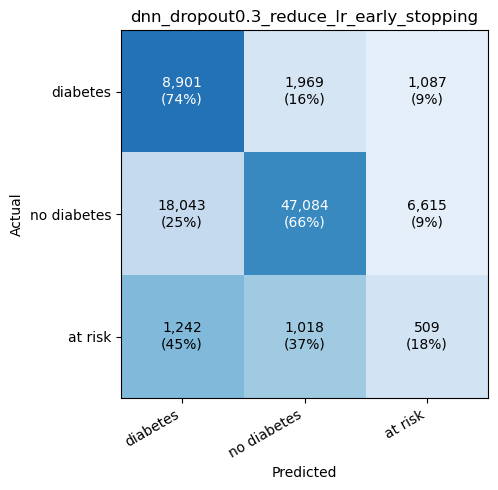

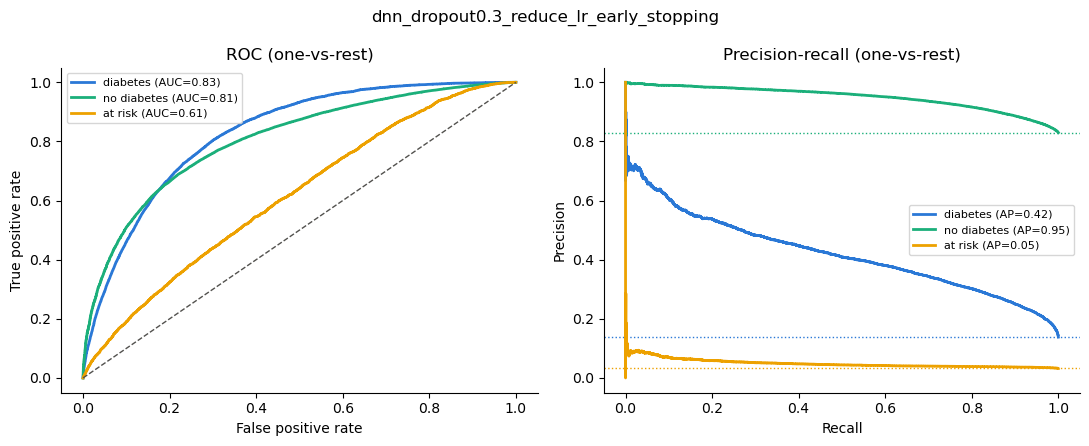

,network,"<Functional n...t, built=True>"
Name,Type,Value
classes_,"ndarray[int64](3,)","[1,3,4]"


In [81]:
best_epoch = int(np.argmax(early_stopping_history.history["val_pr_auc"])) + 1
print("stopped after", len(early_stopping_history.history["loss"]), "epochs | restored epoch", best_epoch)

dnn_config = {"model": "Keras MLP", "hidden_units": "256-128-64-64", "dropout_rate": 0.3,
              "learning_rate": 1e-3, "max_epochs": 50, "class_weight": "balanced",
              "scheduler": "ReduceLROnPlateau(val_loss, factor 0.5, patience 3, min_lr 1e-5)",
              "early_stopping": "val_pr_auc, max, patience 7, restore best weights"}
log_experiment("dnn_dropout0.3_reduce_lr_early_stopping", TrainedNetworkAdapter(early_stopping_model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


In [82]:
small_combined_model = compiled_network(
    network_model=build_network(hidden_units=(64, 32), dropout_rate=0.3),
    metrics=keras_metrics(),
)

reduce_learning_rate = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1,
)
early_stopping = EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=10,
    restore_best_weights=True,
    verbose=1,
)
small_combined_history = train_network(small_combined_model, run_name="dnn_64_32_dropout0.3_reduce_lr_early_stopping",
                                       epochs=50, extra_callbacks=[reduce_learning_rate, early_stopping])

best_epoch = int(np.argmax(small_combined_history.history["val_pr_auc"])) + 1
print("stopped after", len(small_combined_history.history["loss"]), "epochs | restored epoch", best_epoch)


Epoch 1/50
507/507 - 11s - 21ms/step - accuracy: 0.5428 - auc: 0.7035 - f1_macro: 0.3844 - f2_macro: 0.4116 - loss: 1.0035 - pr_auc: 0.4334 - precision_at_risk: 0.0432 - precision_diabetes: 0.2871 - precision_no_diabetes: 0.9357 - recall_at_risk: 0.2933 - recall_diabetes: 0.6369 - recall_no_diabetes: 0.5367 - val_accuracy: 0.5713 - val_auc: 0.7421 - val_f1_macro: 0.4098 - val_f2_macro: 0.4428 - val_loss: 0.9022 - val_pr_auc: 0.4662 - val_precision_at_risk: 0.0488 - val_precision_diabetes: 0.3212 - val_precision_no_diabetes: 0.9493 - val_recall_at_risk: 0.3178 - val_recall_diabetes: 0.7030 - val_recall_no_diabetes: 0.5592 - learning_rate: 0.0010
Epoch 2/50
507/507 - 6s - 12ms/step - accuracy: 0.5608 - auc: 0.7360 - f1_macro: 0.4031 - f2_macro: 0.4376 - loss: 0.9626 - pr_auc: 0.4584 - precision_at_risk: 0.0498 - precision_diabetes: 0.3099 - precision_no_diabetes: 0.9458 - recall_at_risk: 0.3190 - recall_diabetes: 0.7090 - recall_no_diabetes: 0.5454 - val_accuracy: 0.5699 - val_auc: 0.747

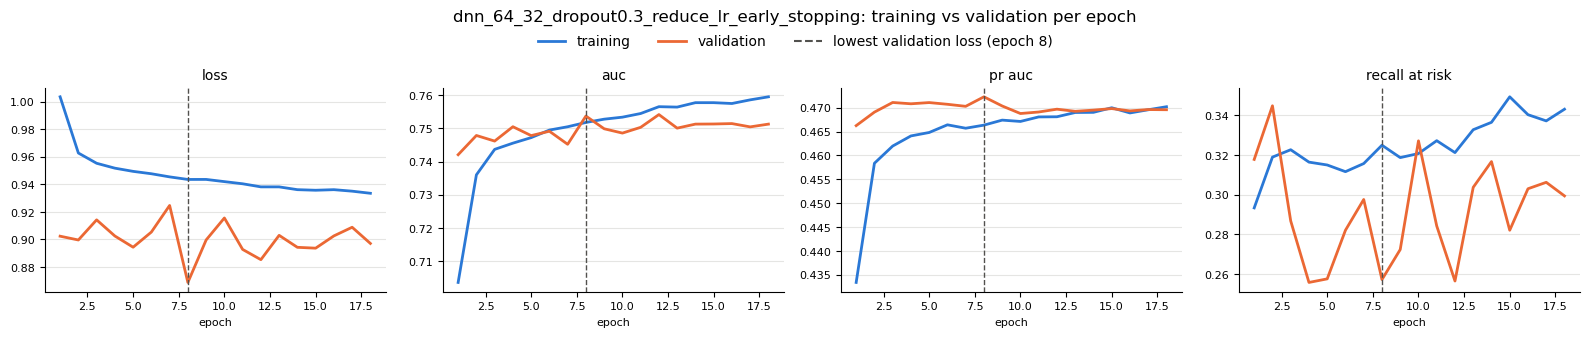

[dnn_64_32_dropout0.3_reduce_lr_early_stopping] SCREENING  sensitivity = 0.826 | precision = 0.304 | F2 = 0.614 | F1 = 0.444 | specificity = 0.611 | flagged = 46.3%
    flagged: diabetes = 0.857 | at risk = 0.688 | diabetics missed = 0.143
    OVERALL  ROC-AUC (OvR) = 0.7537 | macro F1 = 0.4272 | balanced acc = 0.5342 | accuracy = 0.6170
              precision    recall  f1-score   support

    diabetes      0.322     0.734     0.448     11957
 no diabetes      0.945     0.611     0.742     71742
     at risk      0.056     0.257     0.092      2769

    accuracy                          0.617     86468
   macro avg      0.441     0.534     0.427     86468
weighted avg      0.830     0.617     0.681     86468



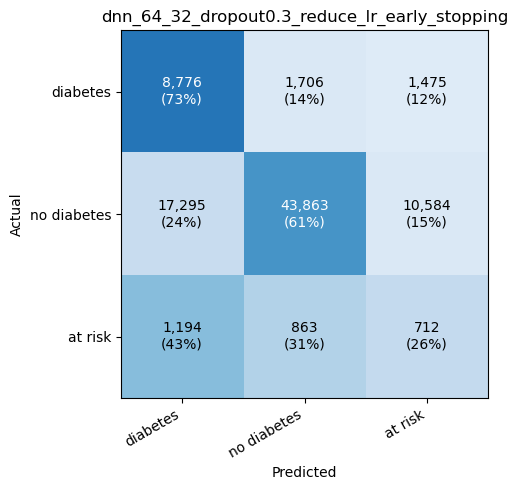

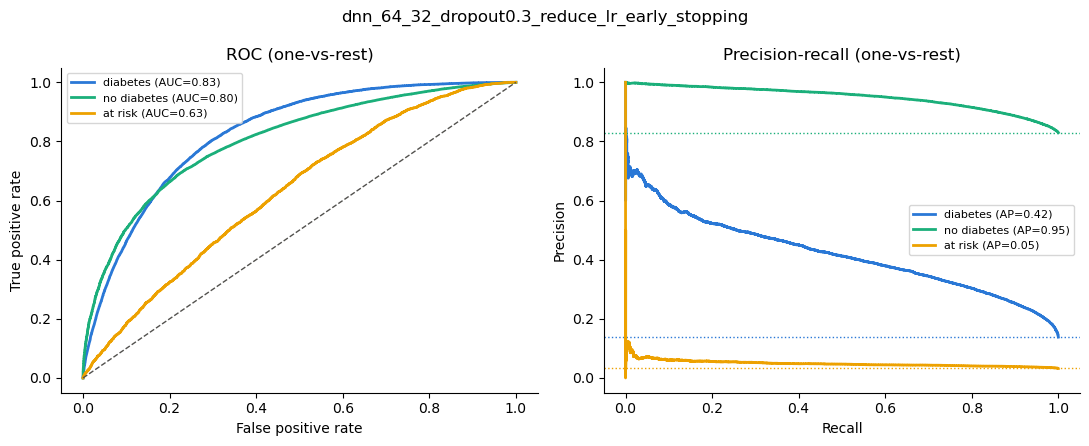

,network,"<Functional n...t, built=True>"
Name,Type,Value
classes_,"ndarray[int64](3,)","[1,3,4]"


In [83]:
plot_training_curves(small_combined_history.history, "dnn_64_32_dropout0.3_reduce_lr_early_stopping",
                     metric_names=["loss", "auc", "pr_auc", "recall_at_risk"])

dnn_config = {"model": "Keras MLP", "hidden_units": "64-32", "dropout_rate": 0.3,
              "learning_rate": 1e-3, "max_epochs": 50, "class_weight": "balanced",
              "scheduler": "ReduceLROnPlateau(val_loss, factor 0.5, patience 3, min_lr 1e-5)",
              "early_stopping": "val_pr_auc, max, patience 10, restore best weights"}
log_experiment("dnn_64_32_dropout0.3_reduce_lr_early_stopping", TrainedNetworkAdapter(small_combined_model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


In [85]:
doubled_combined_model = compiled_network(
    network_model=build_network(hidden_units=(128, 64), dropout_rate=0.3),
    metrics=keras_metrics(),
)

reduce_learning_rate = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1,
)
early_stopping = EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=10,
    restore_best_weights=True,
    verbose=1,
)
doubled_combined_history = train_network(doubled_combined_model, run_name="dnn_64_32_dropout0.3_reduce_lr_early_stopping",
                                       epochs=50, extra_callbacks=[reduce_learning_rate, early_stopping])

best_epoch = int(np.argmax(doubled_combined_history.history["val_pr_auc"])) + 1
print("stopped after", len(doubled_combined_history.history["loss"]), "epochs | restored epoch", best_epoch)


Epoch 1/50
507/507 - 13s - 25ms/step - accuracy: 0.5711 - auc: 0.7194 - f1_macro: 0.4013 - f2_macro: 0.4323 - loss: 0.9826 - pr_auc: 0.4480 - precision_at_risk: 0.0486 - precision_diabetes: 0.3009 - precision_no_diabetes: 0.9379 - recall_at_risk: 0.2935 - recall_diabetes: 0.6656 - recall_no_diabetes: 0.5661 - val_accuracy: 0.5662 - val_auc: 0.7491 - val_f1_macro: 0.4104 - val_f2_macro: 0.4335 - val_loss: 0.9015 - val_pr_auc: 0.4656 - val_precision_at_risk: 0.0500 - val_precision_diabetes: 0.3410 - val_precision_no_diabetes: 0.9454 - val_recall_at_risk: 0.4088 - val_recall_diabetes: 0.5905 - val_recall_no_diabetes: 0.5682 - learning_rate: 0.0010
Epoch 2/50
507/507 - 8s - 16ms/step - accuracy: 0.5756 - auc: 0.7441 - f1_macro: 0.4105 - f2_macro: 0.4453 - loss: 0.9534 - pr_auc: 0.4629 - precision_at_risk: 0.0523 - precision_diabetes: 0.3148 - precision_no_diabetes: 0.9451 - recall_at_risk: 0.3199 - recall_diabetes: 0.7036 - recall_no_diabetes: 0.5641 - val_accuracy: 0.5890 - val_auc: 0.748

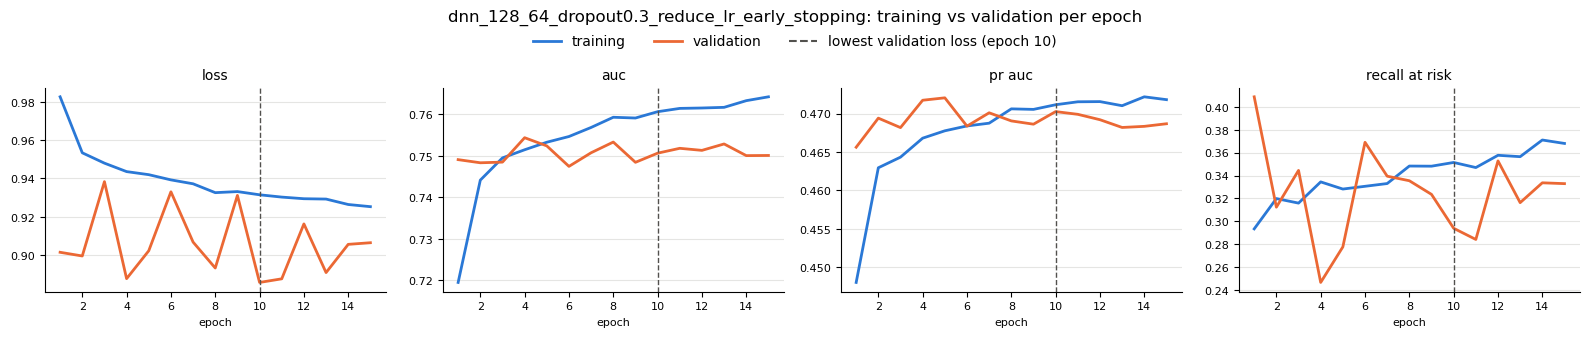

[dnn_128_64_dropout0.3_reduce_lr_early_stopping] SCREENING  sensitivity = 0.835 | precision = 0.295 | F2 = 0.611 | F1 = 0.436 | specificity = 0.590 | flagged = 48.2%
    flagged: diabetes = 0.864 | at risk = 0.707 | diabetics missed = 0.136
    OVERALL  ROC-AUC (OvR) = 0.7524 | macro F1 = 0.4207 | balanced acc = 0.5346 | accuracy = 0.6002
              precision    recall  f1-score   support

    diabetes      0.317     0.736     0.444     11957
 no diabetes      0.946     0.590     0.727     71742
     at risk      0.055     0.278     0.092      2769

    accuracy                          0.600     86468
   macro avg      0.439     0.535     0.421     86468
weighted avg      0.830     0.600     0.667     86468



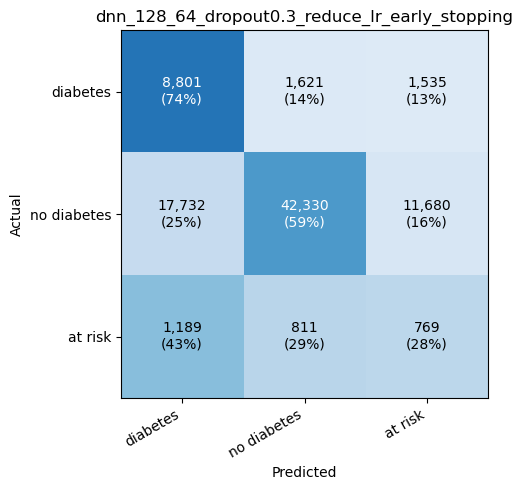

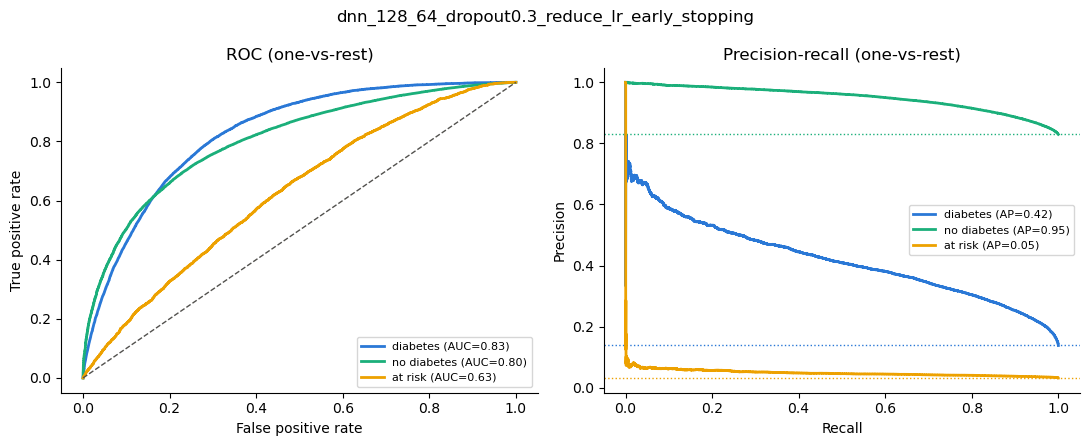

,network,"<Functional n...t, built=True>"
Name,Type,Value
classes_,"ndarray[int64](3,)","[1,3,4]"


In [86]:
plot_training_curves(doubled_combined_history.history, "dnn_128_64_dropout0.3_reduce_lr_early_stopping",
                     metric_names=["loss", "auc", "pr_auc", "recall_at_risk"])

dnn_config = {"model": "Keras MLP", "hidden_units": "128-64", "dropout_rate": 0.3,
              "learning_rate": 1e-3, "max_epochs": 50, "class_weight": "balanced",
              "scheduler": "ReduceLROnPlateau(val_loss, factor 0.5, patience 3, min_lr 1e-5)",
              "early_stopping": "val_pr_auc, max, patience 10, restore best weights"}
log_experiment("dnn_128_64_dropout0.3_reduce_lr_early_stopping", TrainedNetworkAdapter(doubled_combined_model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


In [112]:
focal_model = compiled_network(
    network_model=build_network(hidden_units=(64, 32, 8), dropout_rate=0.3),
    metrics=keras_metrics(),
    loss="categorical_crossentropy",
)

reduce_learning_rate = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1,
)
early_stopping = EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=10,
    restore_best_weights=True,
    verbose=1,
)
focal_history = train_network(focal_model, run_name="dnn_64_16_dropout0.3_reduce_lr_early_stopping_focal",
                              epochs=50, extra_callbacks=[reduce_learning_rate, early_stopping])

best_epoch = int(np.argmax(focal_history.history["val_pr_auc"])) + 1
print("stopped after", len(focal_history.history["loss"]), "epochs | restored epoch", best_epoch)


Epoch 1/50
507/507 - 13s - 26ms/step - accuracy: 0.4815 - auc: 0.6590 - f1_macro: 0.3372 - f2_macro: 0.3661 - loss: 1.0394 - pr_auc: 0.4158 - precision_at_risk: 0.0325 - precision_diabetes: 0.2291 - precision_no_diabetes: 0.9267 - recall_at_risk: 0.1665 - recall_diabetes: 0.7088 - recall_no_diabetes: 0.4558 - val_accuracy: 0.6465 - val_auc: 0.7194 - val_f1_macro: 0.4128 - val_f2_macro: 0.4453 - val_loss: 0.9245 - val_pr_auc: 0.4654 - val_precision_at_risk: 0.0642 - val_precision_diabetes: 0.2807 - val_precision_no_diabetes: 0.9440 - val_recall_at_risk: 0.0509 - val_recall_diabetes: 0.8423 - val_recall_no_diabetes: 0.6369 - learning_rate: 0.0010
Epoch 2/50
507/507 - 7s - 14ms/step - accuracy: 0.5804 - auc: 0.7118 - f1_macro: 0.3932 - f2_macro: 0.4293 - loss: 0.9902 - pr_auc: 0.4477 - precision_at_risk: 0.0490 - precision_diabetes: 0.2699 - precision_no_diabetes: 0.9390 - recall_at_risk: 0.1506 - recall_diabetes: 0.7904 - recall_no_diabetes: 0.5620 - val_accuracy: 0.5980 - val_auc: 0.738

[dnn_64_32_dropout0.3_reduce_lr_early_stopping_focal] SCREENING  sensitivity = 0.819 | precision = 0.310 | F2 = 0.616 | F1 = 0.449 | specificity = 0.625 | flagged = 45.1%
    flagged: diabetes = 0.854 | at risk = 0.670 | diabetics missed = 0.146
    OVERALL  ROC-AUC (OvR) = 0.7528 | macro F1 = 0.4305 | balanced acc = 0.5344 | accuracy = 0.6307
              precision    recall  f1-score   support

    diabetes      0.316     0.760     0.447     11957
 no diabetes      0.944     0.625     0.752     71742
     at risk      0.059     0.218     0.093      2769

    accuracy                          0.631     86468
   macro avg      0.440     0.534     0.431     86468
weighted avg      0.829     0.631     0.689     86468



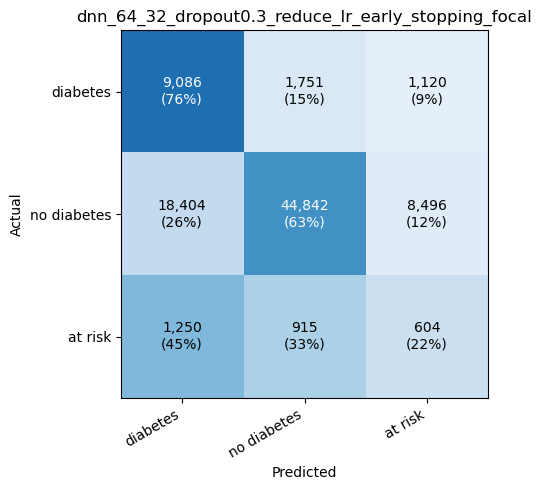

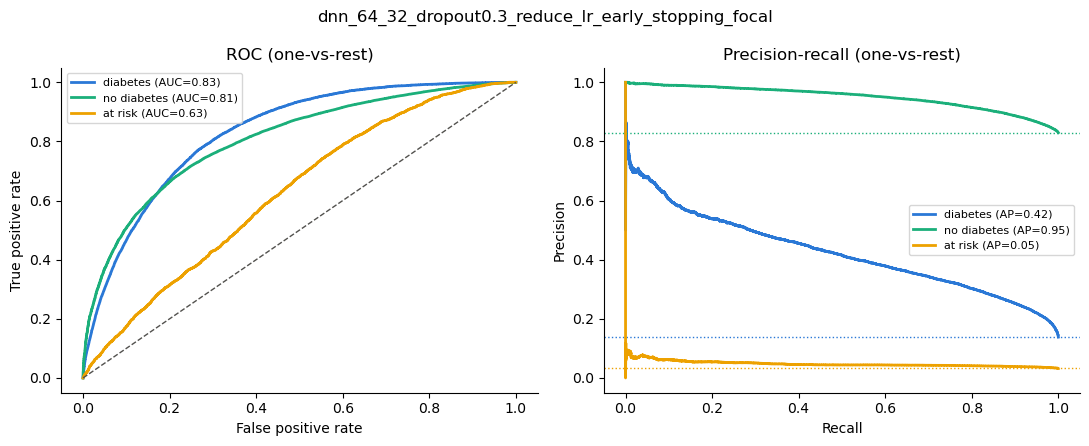

,network,"<Functional n...t, built=True>"
Name,Type,Value
classes_,"ndarray[int64](3,)","[1,3,4]"


In [113]:
dnn_config = {"model": "Keras MLP", "hidden_units": "64-32", "dropout_rate": 0.3,
              "learning_rate": 1e-3, "max_epochs": 50, "class_weight": "balanced",
              "loss": "categorical focal (gamma 2.0) + class weights",
              "scheduler": "ReduceLROnPlateau(val_loss, factor 0.5, patience 3, min_lr 1e-5)",
              "early_stopping": "val_pr_auc, max, patience 10, restore best weights"}
log_experiment("dnn_64_32_dropout0.3_reduce_lr_early_stopping_focal", TrainedNetworkAdapter(focal_model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


In [ ]:
import os, glob, re, shutil, datetime

RUNS_DIR = LOG_DIR      # the "runs" folder
DRY_RUN = True          # True: only print what would happen. Set to False to apply.

# evaluation folder (log_experiment) -> correct label for that experiment
correct_labels = {
    "baseline_neurone_network_20261016-123039": "dnn_256_128_64_64_baseline",
    "dnn_dropout0.3_20261016-123710": "dnn_256_128_64_64_dropout0.3",
    "dnn_dropout0.3_reduce_lr_20261016-124436": "dnn_256_128_64_64_dropout0.3_reduce_lr_val_loss",
    "dnn_dropout0.3_reduce_lr_val_pr_auc_20261016-125245": "dnn_256_128_64_64_dropout0.3_reduce_lr_val_pr_auc",
    "dnn_dropout0.3_reduce_lr_early_stopping_20261016-130502": "dnn_256_128_64_64_dropout0.3_reduce_lr_early_stopping_patience7",
    "dnn_dropout0.3_reduce_lr_early_stopping_20261016-132019": "dnn_256_128_64_64_dropout0.3_reduce_lr_early_stopping_patience10",
    "dnn_64_32_dropout0.3_reduce_lr_early_stopping_20261016-132838": "dnn_64_32_dropout0.3_reduce_lr_early_stopping",
    "dnn_128_64_dropout0.3_reduce_lr_early_stopping_20261016-133704": "dnn_128_64_dropout0.3_reduce_lr_early_stopping",
    "dnn_64_32_dropout0.3_reduce_lr_early_stopping_focal_20261016-152020": "dnn_64_32_dropout0.3_reduce_lr_early_stopping_focal_gamma2",
    "dnn_64_32_dropout0.3_reduce_lr_early_stopping_focal_20261016-152828": "UNKNOWN",   # fill in
    "dnn_64_32_dropout0.3_reduce_lr_early_stopping_focal_20261016-153345": "UNKNOWN",   # fill in
    "dnn_64_32_dropout0.3_reduce_lr_early_stopping_focal_20261016-155243": "UNKNOWN",   # fill in
    "dnn_64_32_dropout0.3_reduce_lr_early_stopping_focal_20261016-155749": "UNKNOWN",   # fill in
    "dnn_64_32_dropout0.3_reduce_lr_early_stopping_focal_20261016-160143": "dnn_64_16_dropout0.3_reduce_lr_early_stopping",
    "dnn_64_32_dropout0.3_reduce_lr_early_stopping_focal_20261016-160641": "dnn_48_16_dropout0.3_reduce_lr_early_stopping",
    "dnn_64_32_dropout0.3_reduce_lr_early_stopping_focal_20261016-161149": "dnn_64_48_dropout0.3_reduce_lr_early_stopping",
    "dnn_64_32_dropout0.3_reduce_lr_early_stopping_focal_20261016-161621": "dnn_64_8_8_dropout0.3_reduce_lr_early_stopping",
    "dnn_64_32_dropout0.3_reduce_lr_early_stopping_focal_20261016-162123": "dnn_64_32_8_dropout0.3_reduce_lr_early_stopping",
}


def apply_action(description, action):
    print(("[dry run] " if DRY_RUN else "") + description)
    if not DRY_RUN:
        action()


# 1. Collect every Keras training run: a train + validation event file pair, created within 60 seconds
keras_event_files = []
for keras_folder in glob.glob(os.path.join(RUNS_DIR, "*")):
    for split_name in ["train", "validation"]:
        for event_path in glob.glob(os.path.join(keras_folder, split_name, "events.out.tfevents.*")):
            created_at = int(os.path.basename(event_path).split(".")[3])
            keras_event_files.append((created_at, keras_folder, split_name, event_path))
keras_event_files.sort()
training_runs = []
for created_at, keras_folder, split_name, event_path in keras_event_files:
    previous_run = training_runs[-1] if training_runs else None
    if (previous_run and previous_run["folder"] == keras_folder
            and created_at - previous_run["start"] < 60 and split_name not in previous_run["files"]):
        previous_run["files"][split_name] = event_path
    else:
        training_runs.append({"start": created_at, "folder": keras_folder, "files": {split_name: event_path}})

# 2. Evaluation folders written by log_experiment (name ends with _YYYYMMDD-HHMMSS)
evaluation_folders = []
for folder_path in glob.glob(os.path.join(RUNS_DIR, "*")):
    folder_name = os.path.basename(folder_path)
    timestamp_match = re.search(r"_(\d{8}-\d{6})$", folder_name)
    if timestamp_match and folder_name in correct_labels:
        evaluation_time = datetime.datetime.strptime(timestamp_match.group(1), "%Y%m%d-%H%M%S").timestamp()
        evaluation_folders.append((evaluation_time, folder_name, timestamp_match.group(1)))

# 3. Pair each training run with the evaluation that followed it, then move / rename / delete
old_keras_folders = set()
for run_index, training_run in enumerate(training_runs):
    next_start = training_runs[run_index + 1]["start"] if run_index + 1 < len(training_runs) else float("inf")
    matching_evaluations = [entry for entry in evaluation_folders if training_run["start"] < entry[0] < next_start]
    if not matching_evaluations:
        for event_path in training_run["files"].values():
            apply_action(f"delete (no evaluation): {os.path.relpath(event_path, RUNS_DIR)}", lambda path=event_path: os.remove(path))
        old_keras_folders.add(training_run["folder"])
        continue
    _, evaluation_name, evaluation_stamp = matching_evaluations[0]
    label = correct_labels[evaluation_name]
    if label == "UNKNOWN":
        print(f"skipped (label unknown): {evaluation_name}")
        continue
    for split_name, event_path in training_run["files"].items():
        target_folder = os.path.join(RUNS_DIR, label, split_name)
        if os.path.abspath(os.path.dirname(event_path)) == os.path.abspath(target_folder):
            continue                                   # already in the right folder
        apply_action(f"move {os.path.relpath(event_path, RUNS_DIR)} -> {label}/{split_name}/",
                     lambda path=event_path, target=target_folder: (os.makedirs(target, exist_ok=True), shutil.move(path, target)))
    old_keras_folders.add(training_run["folder"])
    new_evaluation_name = f"{label}_{evaluation_stamp}"
    if new_evaluation_name != evaluation_name:
        apply_action(f"rename {evaluation_name} -> {new_evaluation_name}",
                     lambda old=evaluation_name, new=new_evaluation_name: os.rename(os.path.join(RUNS_DIR, old), os.path.join(RUNS_DIR, new)))

# 4. Remove the old Keras folders once they are empty
for keras_folder in sorted(old_keras_folders):
    for split_name in ["train", "validation"]:
        split_folder = os.path.join(keras_folder, split_name)
        if not DRY_RUN and os.path.isdir(split_folder) and not os.listdir(split_folder):
            os.rmdir(split_folder)
    if not DRY_RUN and os.path.isdir(keras_folder) and not os.listdir(keras_folder):
        os.rmdir(keras_folder)
        print(f"removed empty folder: {keras_folder}")


[dry run] delete (no evaluation): baseline_neurone_network/train/events.out.tfevents.1792141372.bode-murairi-HP-ProBook-450-15-6-inch-G10-Notebook-PC.237384.8.v2
[dry run] delete (no evaluation): baseline_neurone_network/validation/events.out.tfevents.1792141387.bode-murairi-HP-ProBook-450-15-6-inch-G10-Notebook-PC.237384.9.v2
[dry run] delete (no evaluation): dnn_dropout0.3/train/events.out.tfevents.1792141807.bode-murairi-HP-ProBook-450-15-6-inch-G10-Notebook-PC.237384.10.v2
[dry run] delete (no evaluation): dnn_dropout0.3/validation/events.out.tfevents.1792141824.bode-murairi-HP-ProBook-450-15-6-inch-G10-Notebook-PC.237384.11.v2
[dry run] delete (no evaluation): dnn_dropout0.3_reduce_lr/train/events.out.tfevents.1792142400.bode-murairi-HP-ProBook-450-15-6-inch-G10-Notebook-PC.237384.12.v2
[dry run] delete (no evaluation): dnn_dropout0.3_reduce_lr/validation/events.out.tfevents.1792142419.bode-murairi-HP-ProBook-450-15-6-inch-G10-Notebook-PC.237384.13.v2
[dry run] delete (no evaluati

## Ensemble models

In [116]:
forest_depth12 = RandomForestClassifier(
    n_estimators=1000,
    class_weight="balanced_subsample",
    max_depth=12,
    min_samples_leaf=100,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
).fit(X_train, Y_train)


In [117]:
network_member = TrainedNetworkAdapter(focal_model).fit(X_train, Y_train)   # fit() only sets the classes

averaged_val_probabilities = (forest_depth12.predict_proba(X_val) + network_member.predict_proba(X_val)) / 2
averaged_val_predictions = forest_depth12.classes_[np.argmax(averaged_val_probabilities, axis=1)]

actually_flagged = is_flagged(Y_val)
predicted_flagged = is_flagged(averaged_val_predictions)
print("F2:", round(fbeta_score(actually_flagged, predicted_flagged, beta=2), 4),
      "| recall:", round(recall_score(actually_flagged, predicted_flagged), 4),
      "| precision:", round(precision_score(actually_flagged, predicted_flagged), 4),
      "| F1:", round(f1_score(actually_flagged, predicted_flagged), 4),
      "| ROC-AUC:", round(roc_auc_score(Y_val, averaged_val_probabilities, multi_class="ovr"), 4))


F2: 0.6172 | recall: 0.8174 | precision: 0.3118 | F1: 0.4514 | ROC-AUC: 0.7554


In [115]:
comparison_columns = [
    "run_name",
    "screen_f2", "screen_f1", "screen_sensitivity", "screen_precision", "screen_specificity",
    "screen_sensitivity/diabetes", "screen_sensitivity/at risk", "missed/diabetes", "pct_flagged",
    "val_recall/diabetes", "val_recall/at risk", "val_precision/diabetes", "val_precision/at risk",
    "val_pr_auc/diabetes", "val_pr_auc/at risk", "val_roc_auc_ovr", "val_f1_macro",
]
results_table = pd.DataFrame(results_log)
results_table[[column for column in comparison_columns if column in results_table.columns]] \
    .sort_values("screen_f2", ascending=False)


,run_name,screen_f2,screen_f1,screen_sensitivity,screen_precision,screen_specificity,screen_sensitivity/diabetes,screen_sensitivity/at risk,missed/diabetes,pct_flagged,val_recall/diabetes,val_recall/at risk,val_precision/diabetes,val_precision/at risk,val_pr_auc/diabetes,val_pr_auc/at risk,val_roc_auc_ovr,val_f1_macro
17,dnn_64_32_dropout0.3_reduce_lr_early_stopping_...,0.6162,0.4493,0.8190,0.3095,0.6250,0.8536,0.6696,0.1464,45.0571,0.7599,0.2181,0.3161,0.0591,0.4243,0.0478,0.7528,0.4305
5,dnn_dropout0.3_reduce_lr_early_stopping,0.6159,0.4592,0.7972,0.3225,0.6563,0.8353,0.6324,0.1647,42.0930,0.7444,0.1838,0.3158,0.0620,0.4206,0.0496,0.7488,0.4364
12,dnn_64_32_dropout0.3_reduce_lr_early_stopping_...,0.6158,0.4482,0.8202,0.3084,0.6223,0.8536,0.6761,0.1464,45.3035,0.7637,0.2109,0.3114,0.0593,0.4237,0.0443,0.7436,0.4284
13,dnn_64_32_dropout0.3_reduce_lr_early_stopping_...,0.6156,0.4350,0.8512,0.2921,0.5766,0.8807,0.7237,0.1193,49.6241,0.7724,0.2503,0.3102,0.0527,0.4162,0.0471,0.7502,0.4158
10,dnn_64_32_dropout0.3_reduce_lr_early_stopping_...,0.6149,0.4422,0.8313,0.3012,0.6042,0.8633,0.6927,0.1367,46.9954,0.7607,0.2304,0.3121,0.0555,0.4234,0.0429,0.7435,0.4231
6,dnn_64_32_dropout0.3_reduce_lr_early_stopping,0.6144,0.4440,0.8255,0.3037,0.6114,0.8573,0.6883,0.1427,46.3015,0.7340,0.2571,0.3219,0.0558,0.4187,0.0491,0.7537,0.4272
16,dnn_64_32_dropout0.3_reduce_lr_early_stopping_...,0.6143,0.4473,0.8179,0.3079,0.6226,0.8509,0.6753,0.1491,45.2422,0.7395,0.2282,0.3256,0.0528,0.4225,0.0419,0.7391,0.4293
8,dnn_64_32_dropout0.3_reduce_lr_early_stopping_...,0.6142,0.4376,0.8402,0.2959,0.5896,0.8715,0.7049,0.1285,48.3636,0.7693,0.2315,0.3078,0.0537,0.4222,0.0423,0.7408,0.4179
9,dnn_64_32_dropout0.3_reduce_lr_early_stopping_...,0.6117,0.4324,0.8452,0.2905,0.5763,0.8748,0.7176,0.1252,49.5490,0.7575,0.2687,0.3119,0.0539,0.4220,0.0403,0.7373,0.4161
11,dnn_64_32_dropout0.3_reduce_lr_early_stopping_...,0.6115,0.4417,0.8223,0.3019,0.6097,0.8523,0.6927,0.1477,46.3859,0.7335,0.2607,0.3224,0.0559,0.4224,0.0426,0.7432,0.4269


###### %load_ext tensorboard
%tensorboard --logdir {LOG_DIR}

Citations:
1. Vounzoulaki E, Khunti K, Abner SC, Tan BK, Davies MJ, Gillies CL. Progression to type 2 diabetes in women with a known history of gestational diabetes: systematic review and meta-analysis. BMJ. 2020;369:m1361.
https://www.bmj.com/content/bmj/369/bmj.m1361.full.pdf